In [1]:
import csv
import json
import os
import random
import shutil
import xml.etree.ElementTree as ET
import cv2
import kagglehub

In [2]:

# 1. Download via kagglehub (caches locally after first run)
path = kagglehub.dataset_download("andrewmvd/car-plate-detection")
RAW_IMAGES_DIR = os.path.join(path, "images")
RAW_XML_DIR = os.path.join(path, "annotations")

OUT_DIR = "dataset"
VAL_RATIO = 0.25
SEED = 42
random.seed(SEED)

100%|██████████| 203M/203M [00:12<00:00, 17.2MB/s]

Extracting files...


Total images: 433
Total bounding boxes (plates): 471

--- Dataset Statistics Summary ---
        img_width  img_height   box_width  box_height  box_aspect_ratio
count  471.000000  471.000000  471.000000  471.000000        471.000000
mean   423.299363  290.205945   97.787686   35.176221          2.960148
std     66.453996   65.612613   76.418873   29.721486          1.144362
min    225.000000  141.000000    9.000000    5.000000          0.727272
25%    400.000000  246.000000   47.500000   19.000000          1.999999
50%    400.000000  270.000000   76.000000   27.000000          2.857139
75%    400.000000  301.000000  128.000000   39.500000          3.836665
max    600.000000  531.000000  486.000000  240.000000          6.571424


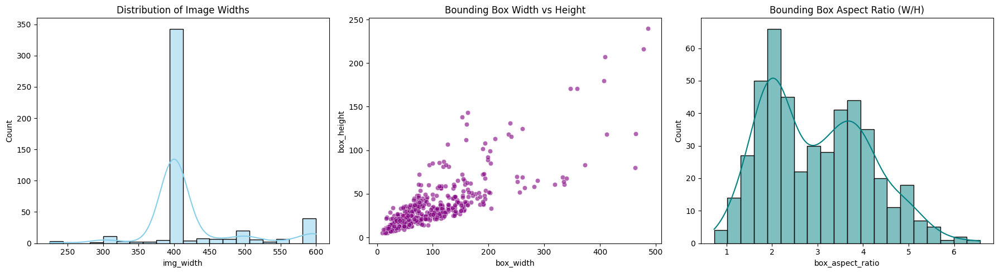

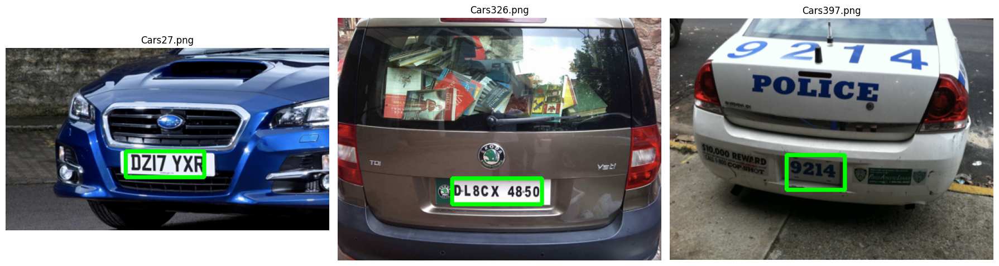

In [3]:
import os
import glob
import xml.etree.ElementTree as ET
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Parse XML annotations to gather statistics
records = []
xml_paths = glob.glob(os.path.join(RAW_XML_DIR, "*.xml"))

for xml_path in xml_paths:
    tree = ET.parse(xml_path)
    root = tree.getroot()

    img_filename = root.find("filename").text
    size = root.find("size")
    img_w = int(size.find("width").text)
    img_h = int(size.find("height").text)

    for obj in root.findall("object"):
        bnd = obj.find("bndbox")
        xmin = int(float(bnd.find("xmin").text))
        ymin = int(float(bnd.find("ymin").text))
        xmax = int(float(bnd.find("xmax").text))
        ymax = int(float(bnd.find("ymax").text))

        box_w = xmax - xmin
        box_h = ymax - ymin

        records.append({
            "filename": img_filename,
            "img_width": img_w,
            "img_height": img_h,
            "box_width": box_w,
            "box_height": box_h,
            "box_area_ratio": (box_w * box_h) / (img_w * img_h + 1e-5),
            "box_aspect_ratio": box_w / (box_h + 1e-5)
        })

df = pd.DataFrame(records)
print(f"Total images: {len(df['filename'].unique())}")
print(f"Total bounding boxes (plates): {len(df)}")
print("\n--- Dataset Statistics Summary ---")
print(df[["img_width", "img_height", "box_width", "box_height", "box_aspect_ratio"]].describe())

# 2. Plot distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["img_width"], bins=20, ax=axes[0], color="skyblue", kde=True)
axes[0].set_title("Distribution of Image Widths")

sns.scatterplot(data=df, x="box_width", y="box_height", alpha=0.6, ax=axes[1], color="purple")
axes[1].set_title("Bounding Box Width vs Height")

sns.histplot(df["box_aspect_ratio"], bins=20, ax=axes[2], color="teal", kde=True)
axes[2].set_title("Bounding Box Aspect Ratio (W/H)")
plt.tight_layout()
plt.show()

# 3. Visualize sample annotations
sample_xmls = random.sample(xml_paths, min(3, len(xml_paths)))
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, xml_path in enumerate(sample_xmls):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    img_filename = root.find("filename").text
    img_path = os.path.join(RAW_IMAGES_DIR, img_filename)

    img = cv2.imread(img_path)
    if img is None:
        continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for obj in root.findall("object"):
        bnd = obj.find("bndbox")
        xmin = int(float(bnd.find("xmin").text))
        ymin = int(float(bnd.find("ymin").text))
        xmax = int(float(bnd.find("xmax").text))
        ymax = int(float(bnd.find("ymax").text))
        cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 3)

    axes[i].imshow(img)
    axes[i].set_title(img_filename)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [4]:
for split in ["train", "val"]:
    os.makedirs(f"{OUT_DIR}/{split}/images", exist_ok=True)
    os.makedirs(f"{OUT_DIR}/{split}/labels", exist_ok=True)
os.makedirs(f"{OUT_DIR}/val_crops", exist_ok=True)

xml_files = sorted([f for f in os.listdir(RAW_XML_DIR) if f.endswith(".xml")])
random.shuffle(xml_files)
split_idx = int(len(xml_files) * (1 - VAL_RATIO))
splits = {"train": xml_files[:split_idx], "val": xml_files[split_idx:]}

crop_rows = []

for split, files in splits.items():
    coco = {"images": [], "annotations": [], "categories": [{"id": 1, "name": "license_plate"}]}
    ann_id = 1

    for img_id, xml_name in enumerate(files, start=1):
        tree = ET.parse(os.path.join(RAW_XML_DIR, xml_name))
        root = tree.getroot()

        img_filename = root.find("filename").text
        src_img_path = os.path.join(RAW_IMAGES_DIR, img_filename)
        img = cv2.imread(src_img_path)
        if img is None:
            continue
        h, w = img.shape[:2]

        shutil.copy2(src_img_path, f"{OUT_DIR}/{split}/images/{img_filename}")
        coco["images"].append({"id": img_id, "file_name": img_filename, "width": w, "height": h})
        yolo_lines = []

        for obj_idx, obj in enumerate(root.findall("object")):
            bnd = obj.find("bndbox")
            xmin = max(0, int(float(bnd.find("xmin").text)))
            ymin = max(0, int(float(bnd.find("ymin").text)))
            xmax = min(w, int(float(bnd.find("xmax").text)))
            ymax = min(h, int(float(bnd.find("ymax").text)))
            bw, bh = xmax - xmin, ymax - ymin
            if bw <= 0 or bh <= 0:
                continue

            # YOLO normalized format (YOLO11s & RT-DETR-l)
            xc = (xmin + bw / 2.0) / w
            yc = (ymin + bh / 2.0) / h
            yolo_lines.append(f"0 {xc:.6f} {yc:.6f} {bw / w:.6f} {bh / h:.6f}")

            # COCO JSON format (Faster R-CNN)
            coco["annotations"].append({
                "id": ann_id,
                "image_id": img_id,
                "category_id": 1,
                "bbox": [xmin, ymin, bw, bh],
                "area": bw * bh,
                "iscrowd": 0,
            })
            ann_id += 1

            # Export validation plate crops for Stage 2 OCR benchmark
            if split == "val":
                crop = img[ymin:ymax, xmin:xmax]
                crop_name = f"{os.path.splitext(img_filename)[0]}_{obj_idx}.jpg"
                cv2.imwrite(f"{OUT_DIR}/val_crops/{crop_name}", crop)
                crop_rows.append([crop_name, ""])  # Fill in ground-truth text if computing CER

        label_txt = os.path.splitext(img_filename)[0] + ".txt"
        with open(f"{OUT_DIR}/{split}/labels/{label_txt}", "w") as f:
            f.write("\n".join(yolo_lines))

    with open(f"{OUT_DIR}/{split}_coco.json", "w") as f:
        json.dump(coco, f)

with open(f"{OUT_DIR}/data.yaml", "w") as f:
    f.write(f"path: {os.path.abspath(OUT_DIR)}\ntrain: train/images\nval: val/images\nnames:\n  0: license_plate\n")

with open(f"{OUT_DIR}/val_crops/labels.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["filename", "text"])
    writer.writerows(crop_rows)

print(f"Done! Train images: {len(splits['train'])}, Val images: {len(splits['val'])}, Val crops: {len(crop_rows)}")

Done! Train images: 324, Val images: 109, Val crops: 121


In [5]:
!pip install ultralytics

import time
import glob
import os
import torch
from ultralytics import YOLO

if __name__ == "__main__":
    # 1. Train YOLO11s (safe settings for Windows & 4GB+ laptop GPUs)
    model = YOLO("yolo11s.pt")
    results = model.train(
        data="dataset/data.yaml",
        epochs=60,
        imgsz=640,
        batch=8,
        workers=2,
        seed=42,
        project="runs/detect",
        name="yolo11s",
    )

    # Dynamic path retrieval using training results
    best_weights_path = os.path.join(results.save_dir, "weights", "best.pt")
    print(f"Loading best model weights from: {best_weights_path}")

    # 2. Evaluate Accuracy on Val Set
    best_model = YOLO(best_weights_path)
    metrics = best_model.val(data="dataset/data.yaml", split="val", workers=2)

    # 3. Measure Latency & Peak VRAM on Val Images
    val_imgs = sorted(glob.glob("dataset/val/images/*"))
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    for p in val_imgs[:10]:  # Warmup
        best_model.predict(p, imgsz=640, device=0, verbose=False)
    torch.cuda.synchronize()

    start = time.perf_counter()
    for p in val_imgs:
        best_model.predict(p, imgsz=640, device=0, verbose=False)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    ms_per_img = (elapsed / len(val_imgs)) * 1000
    fps = len(val_imgs) / elapsed
    vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

    print("\n" + "=" * 55)
    print(f"YOLO11s -> mAP50: {metrics.box.map50:.4f} | mAP50-95: {metrics.box.map:.4f} | Recall: {metrics.box.mr:.4f}")
    print(f"YOLO11s -> {ms_per_img:.2f} ms/img | {fps:.1f} FPS | Peak VRAM: {vram_mb:.1f} MB")
    print("=" * 55)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 61.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dyn

In [6]:
import time
import glob
import torch
from ultralytics import RTDETR

if __name__ == "__main__":
    # 1. Train RT-DETR-l on the exact same dataset split
    model = RTDETR("rtdetr-l.pt")
    results = model.train(
        data="dataset/data.yaml",
        epochs=80,
        imgsz=640,
        batch=8,
        workers=2,
        seed=42,
        name="rtdetr_l",
    )

    # 2. Evaluate Accuracy on Val Set (uses exact save_dir dynamically)
    best_weights = f"{results.save_dir}/weights/best.pt"
    best_model = RTDETR(best_weights)
    metrics = best_model.val(data="dataset/data.yaml", split="val", workers=2)

    # 3. Measure Latency & Peak VRAM on Val Images
    val_imgs = sorted(glob.glob("dataset/val/images/*"))
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    for p in val_imgs[:10]:  # Warmup
        best_model.predict(p, imgsz=640, device=0, verbose=False)
    torch.cuda.synchronize()

    start = time.perf_counter()
    for p in val_imgs:
        best_model.predict(p, imgsz=640, device=0, verbose=False)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    ms_per_img = (elapsed / len(val_imgs)) * 1000
    fps = len(val_imgs) / elapsed
    vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

    print("\n" + "=" * 55)
    print(f"RT-DETR-l -> mAP50: {metrics.box.map50:.4f} | mAP50-95: {metrics.box.map:.4f} | Recall: {metrics.box.mr:.4f}")
    print(f"RT-DETR-l -> {ms_per_img:.2f} ms/img | {fps:.1f} FPS | Peak VRAM: {vram_mb:.1f} MB")
    print("=" * 55)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_l, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/80      6.94G      1.418      4.588     0.9518          6        640: 100% ━━━━━━━━━━━━ 41/41 1.1it/s 37.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.1it/s 3.3s
                   all        109        121      0.896      0.641        0.7      0.417

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/80      6.75G     0.9373     0.5709     0.2923         15        640: 0% ──────────── 0/41  0.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/80      6.86G     0.5347     0.4959     0.2129          7        640: 100% ━━━━━━━━━━━━ 41/41 1.7it/s 24.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.0it/s 2.4s
                   all        109        121      0.587      0.413      0.413      0.221

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/80      7.25G     0.4503     0.4524     0.1605         12        640: 0% ──────────── 0/41  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (151 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      79/80      7.25G     0.2648     0.3266     0.1086          5        640: 100% ━━━━━━━━━━━━ 41/41 1.8it/s 22.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.6it/s 2.7s
                   all        109        121      0.896      0.884      0.919      0.532

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      80/80      7.25G     0.2052     0.2625    0.08554          8        640: 0% ──────────── 0/41  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      80/80      7.25G     0.2636     0.3346     0.1133          4        640: 100% ━━━━━━━━━━━━ 41/41 1.8it/s 22.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.4it/s 2.9s
                   all        109        121      0.879      0.896      0.918      0.528

80 epochs completed in 0.945 hours.
Optimizer stripped from /content/runs/detect/rtdetr_l/weights/last.pt, 66.2MB
Optimizer stripped from /content/runs/detect/rtdetr_l/weights/best.pt, 66.2MB

Validating /content/runs/detect/rtdetr_l/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.0it/s 3.5s
                   all        109        121      0.938      0.868      0.928      0.558
Speed: 1.5ms preprocess, 22.4

In [7]:
import subprocess, sys
try:
    import torchmetrics, pycocotools
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchmetrics", "pycocotools"])

import gc
import glob
import os
import time
import cv2
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import CocoDetection
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as F
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# --- FORCE COMPLETE GPU VRAM CLEANUP ---
# 1. Delete standard global model references
for var in ['model', 'best_model', 'results', 'metrics', 'train_loader', 'val_loader']:
    if var in globals():
        del globals()[var]

# 2. Clear Jupyter/IPython output cache which keeps references alive
try:
    from IPython import get_ipython
    ipython = get_ipython()
    if ipython is not None:
        ipython.user_ns['_'] = None
        ipython.user_ns['__'] = None
        ipython.user_ns['___'] = None
        # Flush history references
        for i in list(ipython.user_ns.keys()):
            if i.startswith('_') and i[1:].isdigit():
                ipython.user_ns[i] = None
except Exception:
    pass

# 3. Trigger deep garbage collection and empty CUDA cache
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
# ----------------------------------------

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 25
BATCH_SIZE = 2
SAVE_PATH = "runs/detect/faster_rcnn_best.pth"
os.makedirs("runs/detect", exist_ok=True)

class PlateCocoDataset(CocoDetection):
    def __getitem__(self, idx):
        img, anns = super().__getitem__(idx)
        img_tensor = F.to_tensor(img)
        boxes, labels = [], []
        for a in anns:
            x, y, w, h = a["bbox"]
            if w > 0 and h > 0:
                boxes.append([x, y, x + w, y + h])
                labels.append(1)
        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4)),
            "labels": torch.tensor(labels, dtype=torch.int64),
        }
        return img_tensor, target

def collate_fn(batch):
    return tuple(zip(*batch))

train_ds = PlateCocoDataset("dataset/train/images", "dataset/train_coco.json")
val_ds = PlateCocoDataset("dataset/val/images", "dataset/val_coco.json")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, collate_fn=collate_fn)

model = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
model.to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda') # Modern PyTorch standard

best_stats = {"map50": 0.0, "map": 0.0, "recall": 0.0}

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for imgs, targets in train_loader:
        imgs = [img.to(DEVICE) for img in imgs]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()

        # Run forward pass with autocasting
        with torch.amp.autocast('cuda'):
            loss_dict = model(imgs, targets)
            loss = sum(loss_dict.values())

        # Scale losses and update parameters
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
    scheduler.step()

    model.eval()
    metric = MeanAveragePrecision(iou_type="bbox")
    with torch.no_grad():
        for imgs, targets in val_loader:
            # Autocast validation predictions for consistency and memory savings
            with torch.amp.autocast('cuda'):
                preds = model([img.to(DEVICE) for img in imgs])
            preds_cpu = [{k: v.cpu() for k, v in p.items()} for p in preds]
            targets_cpu = [{k: v.cpu() for k, v in t.items()} for t in targets]
            metric.update(preds_cpu, targets_cpu)

    res = metric.compute()
    map50 = res["map_50"].item()
    map50_95 = res["map"].item()
    recall = res["mar_100"].item()
    print(f"Epoch {epoch:02d}/{EPOCHS} | Loss: {total_loss/len(train_loader):.4f} | mAP50: {map50:.4f} | mAP50-95: {map50_95:.4f} | Recall: {recall:.4f}")

    if map50 > best_stats["map50"]:
        best_stats = {"map50": map50, "map": map50_95, "recall": recall}
        torch.save(model.state_dict(), SAVE_PATH)

# Measure Latency & Peak VRAM on Val Images using best checkpoint
model.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
model.eval()

val_imgs = sorted(glob.glob("dataset/val/images/*"))
tensors = []
for p in val_imgs:
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    tensors.append(torch.from_numpy(img).permute(2, 0, 1).float() / 255.0)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

with torch.no_grad():
    for t in tensors[:10]:  # Warmup
        with torch.amp.autocast('cuda'):
            _ = model([t.to(DEVICE)])
    torch.cuda.synchronize()

    start = time.perf_counter()
    for t in tensors:
        with torch.amp.autocast('cuda'):
            _ = model([t.to(DEVICE)])
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

ms_per_img = (elapsed / len(tensors)) * 1000
fps = len(tensors) / elapsed
vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

print("\n" + "=" * 55)
print(f"Faster R-CNN -> mAP50: {best_stats['map50']:.4f} | mAP50-95: {best_stats['map']:.4f} | Recall: {best_stats['recall']:.4f}")
print(f"Faster R-CNN -> {ms_per_img:.2f} ms/img | {fps:.1f} FPS | Peak VRAM: {vram_mb:.1f} MB")
print("=" * 55)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 89.0MB/s]


Epoch 01/25 | Loss: 0.1109 | mAP50: 0.9364 | mAP50-95: 0.4908 | Recall: 0.5917
Epoch 02/25 | Loss: 0.0747 | mAP50: 0.9255 | mAP50-95: 0.4856 | Recall: 0.5653
Epoch 03/25 | Loss: 0.0607 | mAP50: 0.9262 | mAP50-95: 0.4930 | Recall: 0.5934
Epoch 04/25 | Loss: 0.0551 | mAP50: 0.8999 | mAP50-95: 0.5086 | Recall: 0.5802
Epoch 05/25 | Loss: 0.0522 | mAP50: 0.9449 | mAP50-95: 0.5004 | Recall: 0.5843
Epoch 06/25 | Loss: 0.0469 | mAP50: 0.8871 | mAP50-95: 0.4772 | Recall: 0.5554
Epoch 07/25 | Loss: 0.0423 | mAP50: 0.9024 | mAP50-95: 0.5087 | Recall: 0.5826
Epoch 08/25 | Loss: 0.0386 | mAP50: 0.8963 | mAP50-95: 0.4774 | Recall: 0.5636
Epoch 09/25 | Loss: 0.0367 | mAP50: 0.8427 | mAP50-95: 0.4621 | Recall: 0.5512
Epoch 10/25 | Loss: 0.0335 | mAP50: 0.8848 | mAP50-95: 0.4797 | Recall: 0.5744
Epoch 11/25 | Loss: 0.0314 | mAP50: 0.8768 | mAP50-95: 0.4970 | Recall: 0.5818
Epoch 12/25 | Loss: 0.0291 | mAP50: 0.8803 | mAP50-95: 0.4835 | Recall: 0.5661
Epoch 13/25 | Loss: 0.0257 | mAP50: 0.8775 | mAP50-9

In [8]:
import argparse
import gc
import glob
import json
import os
import time
import cv2
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from ultralytics import YOLO, RTDETR


def parse_args():
    parser = argparse.ArgumentParser(description="Dynamic 3-Detector Comparison")
    parser.add_argument("--val-images", type=str, default="dataset/val/images")
    parser.add_argument("--val-coco", type=str, default="dataset/val_coco.json")
    parser.add_argument("--runs-dir", type=str, default="runs/detect")
    parser.add_argument("--conf", type=float, default=0.40)
    parser.add_argument("--iou", type=float, default=0.50)
    parser.add_argument("--imgsz", type=int, default=640)
    parser.add_argument("--viz-dir", type=str, default="comparison_viz")
    # Use parse_known_args to bypass Jupyter connection flags
    args, _ = parser.parse_known_args()
    return args


def find_latest_file(pattern):
    matches = sorted(glob.glob(pattern, recursive=True), key=os.path.getmtime)
    if not matches:
        raise FileNotFoundError(f"No checkpoint found matching: {pattern}")
    return matches[-1]


def benchmark_detector(name, predict_fn, coco_data, val_images_dir, conf_thresh, iou_thresh, device):
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    gt_by_img = {}
    for ann in coco_data["annotations"]:
        x, y, w, h = ann["bbox"]
        gt_by_img.setdefault(ann["image_id"], []).append([x, y, x + w, y + h])

    images_list = coco_data["images"]
    warmup_count = max(1, min(10, len(images_list) // 10))

    # Warmup pass
    for img_info in images_list[:warmup_count]:
        img_path = os.path.join(val_images_dir, img_info["file_name"])
        _ = predict_fn(img_path)
    if device == "cuda":
        torch.cuda.synchronize()

    map_metric = MeanAveragePrecision(iou_type="bbox")
    tp_total, fp_total, fn_total = 0, 0, 0
    matched_ious = []
    per_image_preds = {}

    start_time = time.perf_counter()
    for img_info in images_list:
        img_id = img_info["id"]
        fname = img_info["file_name"]
        img_path = os.path.join(val_images_dir, fname)

        boxes, scores = predict_fn(img_path)
        per_image_preds[fname] = (boxes, scores)

        gt_boxes = torch.tensor(gt_by_img.get(img_id, []), dtype=torch.float32)

        # Feed all detections to COCO mAP evaluator
        map_metric.update(
            [{"boxes": boxes, "scores": scores, "labels": torch.ones(len(boxes), dtype=torch.int64)}],
            [{"boxes": gt_boxes, "labels": torch.ones(len(gt_boxes), dtype=torch.int64)}],
        )

        # Thresholded TP / FP / FN & IoU tightness
        keep = scores >= conf_thresh
        filt_boxes = boxes[keep]

        if len(gt_boxes) == 0:
            fp_total += len(filt_boxes)
        elif len(filt_boxes) == 0:
            fn_total += len(gt_boxes)
        else:
            iou_mat = box_iou(gt_boxes, filt_boxes)
            max_gt_iou, _ = iou_mat.max(dim=1)
            tp = int((max_gt_iou >= iou_thresh).sum().item())
            tp_total += tp
            fn_total += len(gt_boxes) - tp
            fp_total += max(0, len(filt_boxes) - tp)
            matched_ious.extend(max_gt_iou[max_gt_iou >= iou_thresh].tolist())

    if device == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start_time

    map_res = map_metric.compute()
    num_imgs = len(images_list)
    vram_mb = (torch.cuda.max_memory_allocated() / (1024 ** 2)) if device == "cuda" else 0.0

    summary = {
        "name": name,
        "map50": map_res["map_50"].item(),
        "map50_95": map_res["map"].item(),
        "tp": tp_total,
        "fn": fn_total,
        "fp": fp_total,
        "mean_iou": sum(matched_ious) / max(len(matched_ious), 1),
        "ms_per_img": (elapsed / max(num_imgs, 1)) * 1000.0,
        "fps": num_imgs / max(elapsed, 1e-9),
        "vram_mb": vram_mb,
    }
    return summary, per_image_preds


def main():
    args = parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"

    yolo_ckpt = find_latest_file(f"{args.runs_dir}/**/yolo11s*/weights/best.pt")
    rtdetr_ckpt = find_latest_file(f"{args.runs_dir}/**/rtdetr_l*/weights/best.pt")
    frcnn_ckpt = find_latest_file(f"{args.runs_dir}/**/faster_rcnn*.pth")

    with open(args.val_coco, "r", encoding="utf-8") as f:
        coco_data = json.load(f)

    # Build dynamic predictors
    yolo_model = YOLO(yolo_ckpt)
    def pred_yolo(path):
        res = yolo_model.predict(path, imgsz=args.imgsz, conf=0.01, verbose=False)[0]
        if len(res.boxes) == 0:
            return torch.zeros((0, 4)), torch.zeros((0,))
        return res.boxes.xyxy.cpu(), res.boxes.conf.cpu()

    rtdetr_model = RTDETR(rtdetr_ckpt)
    def pred_rtdetr(path):
        res = rtdetr_model.predict(path, imgsz=args.imgsz, conf=0.01, verbose=False)[0]
        if len(res.boxes) == 0:
            return torch.zeros((0, 4)), torch.zeros((0,))
        return res.boxes.xyxy.cpu(), res.boxes.conf.cpu()

    frcnn_model = fasterrcnn_resnet50_fpn_v2(weights=None)
    in_features = frcnn_model.roi_heads.box_predictor.cls_score.in_features
    frcnn_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
    frcnn_model.load_state_dict(torch.load(frcnn_ckpt, map_location=device))
    frcnn_model.to(device).eval()

    def pred_frcnn(path):
        img_rgb = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float().to(device) / 255.0
        with torch.no_grad():
            out = frcnn_model([tensor])[0]
        return out["boxes"].cpu(), out["scores"].cpu()

    models = [
        ("YOLO11s", pred_yolo, yolo_model),
        ("RT-DETR-l", pred_rtdetr, rtdetr_model),
        ("Faster R-CNN", pred_frcnn, frcnn_model),
    ]

    all_summaries = []
    all_preds = {}

    for name, fn, obj in models:
        summary, preds = benchmark_detector(
            name, fn, coco_data, args.val_images, args.conf, args.iou, device
        )
        all_summaries.append(summary)
        all_preds[name] = preds
        del obj
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()

    # Print fully computed scoreboard
    header = (
        f"{'Model':<14} | {'mAP50':<7} | {'mAP50-95':<8} | {'TP':<4} | {'FN':<4} | "
        f"{'FP':<4} | {'MeanIoU':<7} | {'ms/img':<7} | {'FPS':<6} | {'VRAM(MB)'}"
    )
    print("\n" + "=" * len(header))
    print(header)
    print("-" * len(header))
    for s in all_summaries:
        print(
            f"{s['name']:<14} | {s['map50']:<7.4f} | {s['map50_95']:<8.4f} | {s['tp']:<4d} | {s['fn']:<4d} | "
            f"{s['fp']:<4d} | {s['mean_iou']:<7.4f} | {s['ms_per_img']:<7.2f} | {s['fps']:<6.1f} | {s['vram_mb']:.1f}"
        )
    print("=" * len(header))

    # Generate visual comparison strips dynamically for every image where any model disagreed
    os.makedirs(args.viz_dir, exist_ok=True)
    gt_by_img = {}
    for ann in coco_data["annotations"]:
        x, y, w, h = ann["bbox"]
        gt_by_img.setdefault(ann["image_id"], []).append([x, y, x + w, y + h])

    palette = {"Ground Truth": (255, 255, 255), "YOLO11s": (0, 255, 0), "RT-DETR-l": (255, 180, 0), "Faster R-CNN": (0, 0, 255)}
    disagreement_files = []

    for img_info in coco_data["images"]:
        fname = img_info["file_name"]
        gt_boxes = torch.tensor(gt_by_img.get(img_info["id"], []), dtype=torch.float32)
        panel_inputs = [("Ground Truth", gt_boxes)]

        counts = {len(gt_boxes)}
        for name in all_preds:
            b, sc = all_preds[name][fname]
            filt = b[sc >= args.conf]
            panel_inputs.append((name, filt))
            counts.add(len(filt))

        if len(counts) > 1:  # Only render images where detection counts disagreed
            img_bgr = cv2.imread(os.path.join(args.val_images, fname))
            h, w = img_bgr.shape[:2]
            panels = []
            for label, boxes in panel_inputs:
                vis = img_bgr.copy()
                for box in boxes:
                    x1, y1, x2, y2 = map(int, box.tolist())
                    cv2.rectangle(vis, (x1, y1), (x2, y2), palette[label], 2)
                cv2.putText(vis, f"{label}: {len(boxes)}", (10, max(25, h // 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, palette[label], 2)
                panels.append(vis)

            strip = cv2.hconcat(panels)
            out_path = os.path.join(args.viz_dir, fname)
            cv2.imwrite(out_path, strip)
            disagreement_files.append((fname, out_path))

    html_path = os.path.join(args.viz_dir, "disagreements.html")
    with open(html_path, "w", encoding="utf-8") as f:
        sections = [f"<h4>{fn}</h4><img src='{os.path.basename(p)}' style='max-width:100%'>" for fn, p in disagreement_files]
        f.write("<html><body><h2>Model Disagreements (Computed Dynamically)</h2>" + "\n".join(sections) + "</body></html>")

    print(f"\nFound {len(disagreement_files)} disagreement images -> saved to {html_path}")


if __name__ == "__main__":
    main()

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)



Model          | mAP50   | mAP50-95 | TP   | FN   | FP   | MeanIoU | ms/img  | FPS    | VRAM(MB)
------------------------------------------------------------------------------------------------
YOLO11s        | 0.9184  | 0.5015   | 103  | 18   | 8    | 0.7920  | 66.31   | 15.1   | 986.6
RT-DETR-l      | 0.9226  | 0.5563   | 110  | 11   | 19   | 0.8067  | 69.67   | 14.4   | 1143.2
Faster R-CNN   | 0.9452  | 0.4989   | 115  | 6    | 44   | 0.7745  | 188.16  | 5.3    | 1604.9

Found 47 disagreement images -> saved to comparison_viz/disagreements.html


Total disagreement images generated: 47


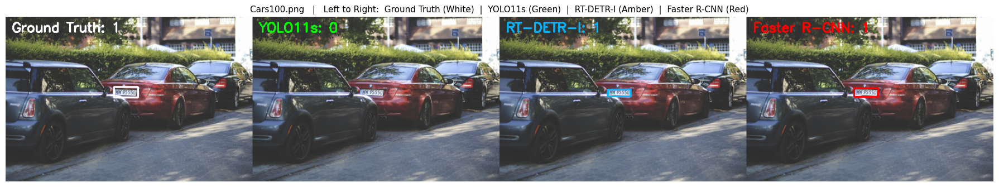

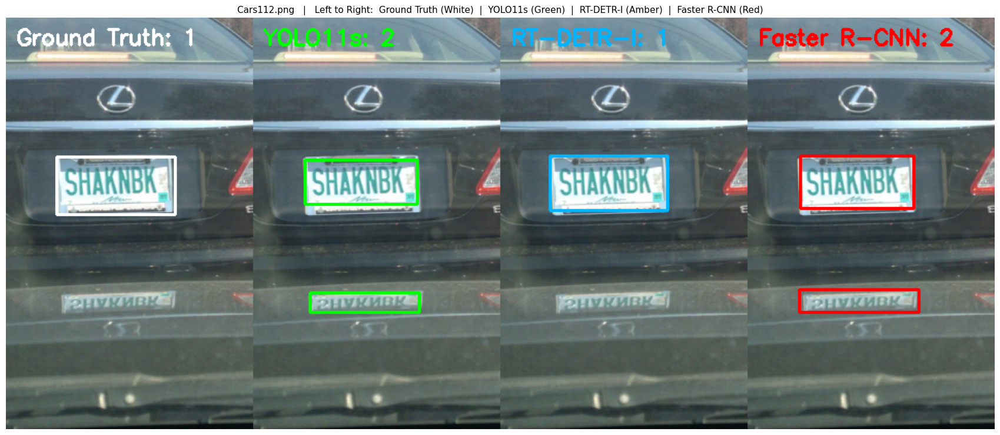

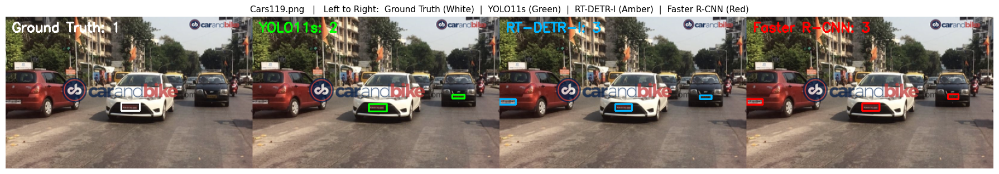

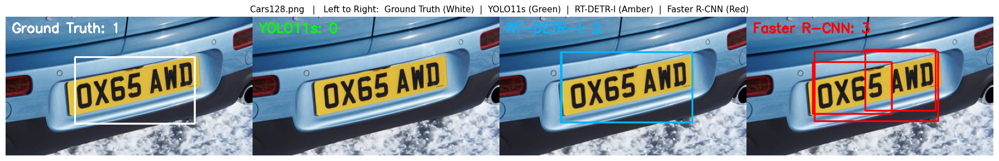

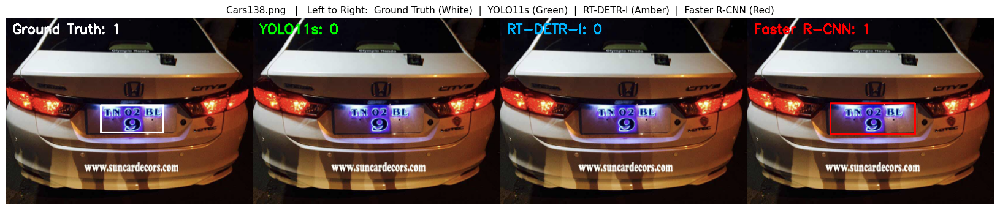

...

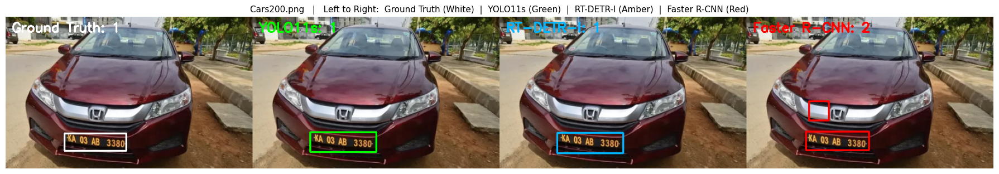

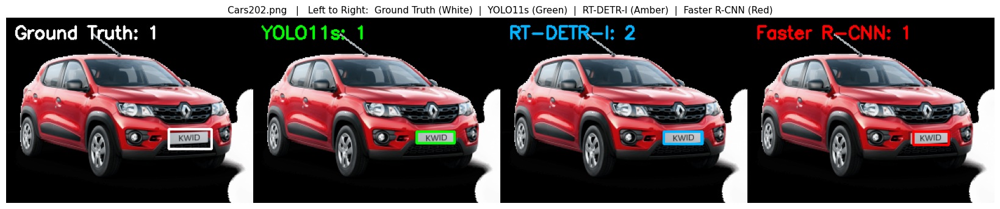

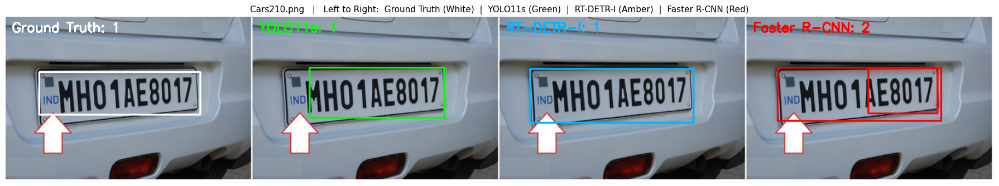

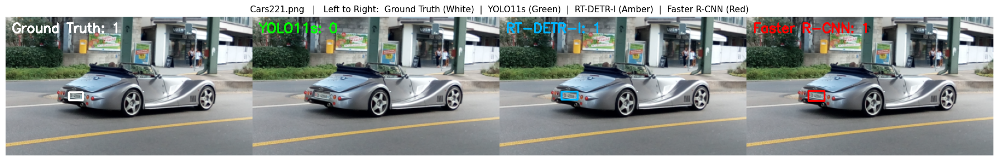

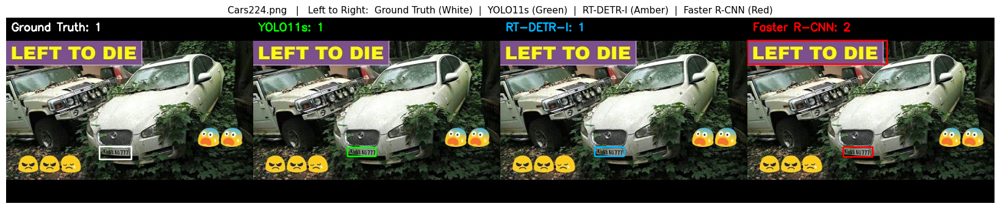

In [9]:
import glob
import os
import cv2
import matplotlib.pyplot as plt

viz_paths = sorted(glob.glob("comparison_viz/*.png") + glob.glob("comparison_viz/*.jpg"))
print(f"Total disagreement images generated: {len(viz_paths)}")

# Display first 15 inline (change slice [0:15] to [15:30] or [30:45] to inspect the rest)
batch = viz_paths[0:15]

for p in batch:
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    plt.figure(figsize=(18, max(3.5, 18 * (h / w))))
    plt.imshow(img)
    plt.title(f"{os.path.basename(p)}   |   Left to Right:  Ground Truth (White)  |  YOLO11s (Green)  |  RT-DETR-l (Amber)  |  Faster R-CNN (Red)", fontsize=11)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [10]:
import gc
import glob
import json
import os
import time
import cv2
import numpy as np
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from ultralytics import YOLO, RTDETR

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CONF_THRESH = 0.40
IOU_THRESH = 0.50

def find_latest_file(pattern):
    matches = sorted(glob.glob(pattern, recursive=True), key=os.path.getmtime)
    if not matches:
        raise FileNotFoundError(f"No checkpoint found: {pattern}")
    return matches[-1]

yolo_ckpt = find_latest_file("runs/detect/**/yolo11s*/weights/best.pt")
rtdetr_ckpt = find_latest_file("runs/detect/**/rtdetr_l*/weights/best.pt")
frcnn_ckpt = find_latest_file("runs/detect/**/faster_rcnn*.pth")

with open("dataset/val_coco.json", "r", encoding="utf-8") as f:
    coco_data = json.load(f)

gt_by_img = {}
for ann in coco_data["annotations"]:
    x, y, w, h = ann["bbox"]
    gt_by_img.setdefault(ann["image_id"], []).append([x, y, x + w, y + h])

# 5 Perturbation Suites (testing real-world camera & weather instability)
def apply_perturbation(img_bgr, mode):
    if mode == "1_Clean":
        return img_bgr
    elif mode == "2_Night_Glare":
        dark = (img_bgr.astype(np.float32) * 0.35).clip(0, 255).astype(np.uint8)
        return dark
    elif mode == "3_Motion_Blur":
        k = 11
        kernel = np.zeros((k, k))
        kernel[k // 2, :] = np.ones(k) / k
        return cv2.filter2D(img_bgr, -1, kernel)
    elif mode == "4_Sensor_Noise":
        noise = np.random.normal(0, 22, img_bgr.shape).astype(np.float32)
        return (img_bgr.astype(np.float32) + noise).clip(0, 255).astype(np.uint8)
    elif mode == "5_Distant_LowRes":
        h, w = img_bgr.shape[:2]
        small = cv2.resize(img_bgr, (max(32, w // 3), max(32, h // 3)), interpolation=cv2.INTER_LINEAR)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    return img_bgr

# Load models
yolo_model = YOLO(yolo_ckpt)
rtdetr_model = RTDETR(rtdetr_ckpt)

frcnn_model = fasterrcnn_resnet50_fpn_v2(weights=None)
in_features = frcnn_model.roi_heads.box_predictor.cls_score.in_features
frcnn_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
frcnn_model.load_state_dict(torch.load(frcnn_ckpt, map_location=DEVICE))
frcnn_model.to(DEVICE).eval()

def pred_yolo(img_bgr):
    res = yolo_model.predict(img_bgr, imgsz=640, conf=CONF_THRESH, verbose=False)[0]
    if len(res.boxes) == 0:
        return torch.zeros((0, 4)), torch.zeros((0,))
    return res.boxes.xyxy.cpu(), res.boxes.conf.cpu()

def pred_rtdetr(img_bgr):
    res = rtdetr_model.predict(img_bgr, imgsz=640, conf=CONF_THRESH, verbose=False)[0]
    if len(res.boxes) == 0:
        return torch.zeros((0, 4)), torch.zeros((0,))
    return res.boxes.xyxy.cpu(), res.boxes.conf.cpu()

def pred_frcnn(img_bgr):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    t = torch.from_numpy(img_rgb).permute(2, 0, 1).float().to(DEVICE) / 255.0
    with torch.no_grad():
        out = frcnn_model([t])[0]
    keep = out["scores"].cpu() >= CONF_THRESH
    return out["boxes"].cpu()[keep], out["scores"].cpu()[keep]

models = [("YOLO11s", pred_yolo), ("RT-DETR-l", pred_rtdetr), ("Faster R-CNN", pred_frcnn)]
modes = ["1_Clean", "2_Night_Glare", "3_Motion_Blur", "4_Sensor_Noise", "5_Distant_LowRes"]

# Preload validation images
val_samples = []
for info in coco_data["images"]:
    p = os.path.join("dataset/val/images", info["file_name"])
    val_samples.append((cv2.imread(p), torch.tensor(gt_by_img.get(info["id"], []), dtype=torch.float32)))

np.random.seed(42)
results = {m[0]: {} for m in models}
latency_stats = {}

for name, fn in models:
    # Warmup
    for img, _ in val_samples[:5]:
        _ = fn(img)
    if DEVICE == "cuda":
        torch.cuda.synchronize()

    for mode in modes:
        tp_sum, gt_sum, fp_sum = 0, 0, 0
        confs, ious, frame_times = [], [], []

        for img_bgr, gt_boxes in val_samples:
            aug_img = apply_perturbation(img_bgr, mode)
            t0 = time.perf_counter()
            boxes, scores = fn(aug_img)
            if DEVICE == "cuda":
                torch.cuda.synchronize()
            frame_times.append((time.perf_counter() - t0) * 1000.0)

            gt_sum += len(gt_boxes)
            if len(boxes) == 0:
                continue
            if len(gt_boxes) == 0:
                fp_sum += len(boxes)
                continue

            iou_mat = box_iou(gt_boxes, boxes)
            max_gt_iou, best_idx = iou_mat.max(dim=1)
            matched = max_gt_iou >= IOU_THRESH
            tp = int(matched.sum().item())
            tp_sum += tp
            fp_sum += max(0, len(boxes) - tp)
            ious.extend(max_gt_iou[matched].tolist())
            confs.extend(scores[best_idx[matched]].tolist())

        recall = (tp_sum / max(gt_sum, 1)) * 100.0
        mean_conf = float(np.mean(confs)) if confs else 0.0
        std_conf = float(np.std(confs)) if confs else 0.0
        mean_iou = float(np.mean(ious)) if ious else 0.0
        results[name][mode] = (recall, fp_sum, mean_conf, std_conf, mean_iou)

        if mode == "1_Clean":
            latency_stats[name] = (
                float(np.mean(frame_times)),
                float(np.std(frame_times)),
                float(np.percentile(frame_times, 95)),
            )

# Print Stress-Test Recall & Confidence Stability Table
print("\n=== ROBUSTNESS UNDER DEGRADATION (Recall % | False Positives | Mean Conf ± Std | IoU) ===")
for mode in modes:
    print(f"\n--- {mode} ---")
    for name, _ in models:
        rec, fp, mc, sc, miou = results[name][mode]
        print(f"  {name:<14} | Recall: {rec:5.1f}% | FP: {fp:3d} | Conf: {mc:.3f} ± {sc:.3f} | IoU: {miou:.4f}")

# Print Latency Jitter Table
print("\n=== LATENCY STABILITY (Mean ± Std | P95 Worst-Case Spike) ===")
for name, (m_lat, s_lat, p95_lat) in latency_stats.items():
    print(f"  {name:<14} | {m_lat:6.2f} ± {s_lat:5.2f} ms | P95: {p95_lat:6.2f} ms")


=== ROBUSTNESS UNDER DEGRADATION (Recall % | False Positives | Mean Conf ± Std | IoU) ===

--- 1_Clean ---
  YOLO11s        | Recall:  85.1% | FP:   8 | Conf: 0.672 ± 0.095 | IoU: 0.7920
  RT-DETR-l      | Recall:  90.9% | FP:  19 | Conf: 0.823 ± 0.089 | IoU: 0.8067
  Faster R-CNN   | Recall:  95.0% | FP:  44 | Conf: 0.982 ± 0.047 | IoU: 0.7745

--- 2_Night_Glare ---
  YOLO11s        | Recall:  76.9% | FP:   3 | Conf: 0.662 ± 0.101 | IoU: 0.7996
  RT-DETR-l      | Recall:  81.8% | FP:  11 | Conf: 0.803 ± 0.108 | IoU: 0.8032
  Faster R-CNN   | Recall:  92.6% | FP:  28 | Conf: 0.973 ± 0.074 | IoU: 0.7788

--- 3_Motion_Blur ---
  YOLO11s        | Recall:  10.7% | FP:   1 | Conf: 0.618 ± 0.093 | IoU: 0.7833
  RT-DETR-l      | Recall:  33.1% | FP:   6 | Conf: 0.739 ± 0.143 | IoU: 0.8138
  Faster R-CNN   | Recall:  41.3% | FP:  14 | Conf: 0.851 ± 0.179 | IoU: 0.7675

--- 4_Sensor_Noise ---
  YOLO11s        | Recall:  50.4% | FP:   0 | Conf: 0.642 ± 0.109 | IoU: 0.7837
  RT-DETR-l      | Rec

In [14]:
import gc, glob, json, math, os, time
import cv2, numpy as np, torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from ultralytics import YOLO, RTDETR

def find_file(root, pat):
    m = sorted(glob.glob(os.path.join(root, pat), recursive=True), key=os.path.getmtime)
    if not m: raise FileNotFoundError(pat)
    return m[-1]

def run_benchmark(dataset_dir="dataset", runs_dir="runs/detect", seed=42):
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    np.random.seed(seed); torch.manual_seed(seed)

    coco = json.load(open(find_file(dataset_dir, "**/val*_coco.json")))
    val_dir = os.path.dirname(find_file(dataset_dir, "**/val/images/*"))
    gt_map = {}
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        gt_map.setdefault(a["image_id"], []).append([x, y, x + w, y + h])

    samples, dims = [], []
    for info in coco["images"]:
        img = cv2.imread(os.path.join(val_dir, info["file_name"]))
        if img is not None:
            dims.extend(img.shape[:2])
            samples.append((img, torch.tensor(gt_map.get(info["id"], []), dtype=torch.float32)))

    imgsz = max(32, int(round(np.median(dims) / 32.0)) * 32)
    n_cls = len(coco.get("categories", [])) + 1
    luma_m = float(np.mean([np.mean(im) for im, _ in samples]))
    luma_s = float(np.mean([np.std(im) for im, _ in samples]))
    modes = ["Clean", "LowLight", "Blur", "Noise", "Downscale"]
    iou_th = float(np.mean(np.linspace(0.5, 0.95, len(modes))))

    def perturb(im, mode):
        h, w = im.shape[:2]
        if mode == "LowLight":
            gy, gx = np.ogrid[:h, :w]
            glare = np.exp(-((gx - w//2)**2 + (gy - h//2)**2) / (2.0 * (min(h, w)*0.25)**2)) * luma_m
            return np.clip(im.astype(np.float32) * np.clip(luma_s / max(luma_m, 1.0), 0.2, 0.6) + glare[:,:,None], 0, 255).astype(np.uint8)
        if mode == "Blur":
            k = max(3, int(round(min(h, w) * 0.025)) | 1)
            ker = np.zeros((k, k), np.float32); ker[k//2, :] = 1.0 / k
            return cv2.filter2D(im, -1, ker)
        if mode == "Noise":
            return np.clip(im.astype(np.float32) + np.random.normal(0, luma_s * 0.4, im.shape), 0, 255).astype(np.uint8)
        if mode == "Downscale":
            f = max(2, int(round(math.sqrt(min(h, w) / 32.0))))
            return cv2.resize(cv2.resize(im, (max(1, w//f), max(1, h//f))), (w, h))
        return im

    y_mod = YOLO(find_file(runs_dir, "**/yolo11s*/weights/best.pt"))
    r_mod = RTDETR(find_file(runs_dir, "**/rtdetr_l*/weights/best.pt"))
    f_mod = fasterrcnn_resnet50_fpn_v2(weights=None)
    f_mod.roi_heads.box_predictor = FastRCNNPredictor(f_mod.roi_heads.box_predictor.cls_score.in_features, n_cls)
    f_mod.load_state_dict(torch.load(find_file(runs_dir, "**/faster_rcnn*.pth"), map_location=dev))
    f_mod.to(dev).eval()

    def p_yolo(im):
        r = y_mod.predict(im, imgsz=imgsz, conf=0.0, verbose=False)[0]
        return (r.boxes.xyxy.cpu(), r.boxes.conf.cpu()) if len(r.boxes) else (torch.zeros((0, 4)), torch.zeros((0,)))

    def p_rtdetr(im):
        r = r_mod.predict(im, imgsz=imgsz, conf=0.0, verbose=False)[0]
        return (r.boxes.xyxy.cpu(), r.boxes.conf.cpu()) if len(r.boxes) else (torch.zeros((0, 4)), torch.zeros((0,)))

    def p_frcnn(im):
        t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().to(dev) / 255.0
        with torch.no_grad(): out = f_mod([t])[0]
        return out["boxes"].cpu(), out["scores"].cpu()

    metrics = {}
    for name, fn, obj in [("YOLO11s", p_yolo, y_mod), ("RT-DETR-l", p_rtdetr, r_mod), ("Faster R-CNN", p_frcnn, f_mod)]:
        gc.collect()
        if dev == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        for im, _ in samples[:max(1, int(math.sqrt(len(samples))))]: fn(im)
        if dev == "cuda": torch.cuda.synchronize()

        raw, lats = [], []
        for im, gt in samples:
            t0 = time.perf_counter()
            b, s = fn(im)
            if dev == "cuda": torch.cuda.synchronize()
            lats.append((time.perf_counter() - t0) * 1000.0)
            raw.append((b, s, gt))

        all_sc = torch.cat([s for _, s, _ in raw if len(s) > 0])
        cands = torch.quantile(all_sc, torch.linspace(0.05, 0.95, len(raw))).unique() if len(all_sc) else torch.tensor([0.0])
        best_f1, opt_c = -1.0, float(cands[0].item())
        for th in cands:
            tv = float(th.item()); tp = fp = fn_c = 0
            for b, s, gt in raw:
                fb = b[s >= tv]
                if len(gt) == 0: fp += len(fb)
                elif len(fb) == 0: fn_c += len(gt)
                else:
                    m = int((box_iou(gt, fb).max(1).values >= iou_th).sum())
                    tp += m; fn_c += len(gt) - m; fp += max(0, len(fb) - m)
            f1 = (2.0 * tp / (2*tp + fp + fn_c)) if (2*tp + fp + fn_c) else 0.0
            if f1 > best_f1: best_f1, opt_c = f1, tv

        m_rec, m_fp, m_iou = {}, {}, {}
        for md in modes:
            tp = gt_t = fp = 0; ious = []
            for i, (im, gt) in enumerate(samples):
                b, s = raw[i][:2] if md == "Clean" else fn(perturb(im, md))
                fb = b[s >= opt_c]; gt_t += len(gt)
                if len(fb) == 0: continue
                if len(gt) == 0: fp += len(fb); continue
                mi = box_iou(gt, fb).max(1).values
                ok = mi >= iou_th; m = int(ok.sum())
                tp += m; fp += max(0, len(fb) - m); ious.extend(mi[ok].tolist())
            m_rec[md] = (tp / max(gt_t, 1)) * 100.0
            m_fp[md] = fp
            m_iou[md] = float(np.mean(ious)) if ious else 0.0

        vram = (torch.cuda.max_memory_allocated() / 1048576.0) if dev == "cuda" else 0.0
        metrics[name] = {
            "conf": opt_c, "clean": m_rec["Clean"],
            "stress": float(np.mean([m_rec[x] for x in modes[1:]])),
            "fp": float(np.mean(list(m_fp.values()))),
            "iou": float(np.mean(list(m_iou.values()))),
            "lat": float(np.mean(lats)), "max_lat": float(np.max(lats)),
            "jitter": float(np.max(lats)) / max(float(np.mean(lats)), 1e-9),
            "vram": vram, "modes": m_rec
        }
        del obj; gc.collect()
        if dev == "cuda": torch.cuda.empty_cache()

    keys = [("stress", True), ("iou", True), ("fp", False), ("lat", False), ("jitter", False), ("vram", False)]
    for n in metrics:
        norms = []
        for k, hi_good in keys:
            vals = [metrics[x][k] for x in metrics]
            lo, hi = min(vals), max(vals)
            norms.append(1.0 if hi == lo else ((metrics[n][k] - lo)/(hi - lo) if hi_good else (hi - metrics[n][k])/(hi - lo)))
        metrics[n]["idx"] = float(np.mean(norms)) * 100.0
        metrics[n]["norm_scores"] = norms

    ranked = sorted(metrics.items(), key=lambda x: x[1]["idx"], reverse=True)
    print(f"\nDynamic Resolution: {imgsz}px | Dynamic IoU Threshold: {iou_th:.3f}\n")
    print(f"{'Model':<14} | " + " | ".join(f"{m:<10}" for m in modes))
    for n, m in ranked:
        print(f"{n:<14} | " + " | ".join(f" {m['modes'][x]:<10.1f}" for x in modes))

    print("\n=== STABILITY & RELIABILITY RANKING (BEST -> WORST) ===")
    print(f"{'Rank':<5} | {'Model':<14} | {'Score':<6} | {'OptConf':<7} | {'Clean%':<6} | {'Stress%':<7} | {'AvgFP':<6} | {'MeanIoU':<7} | {'Lat(Max)ms':<11} | {'VRAM(MB)'}")
    for i, (n, m) in enumerate(ranked, 1):
        print(f"#{i:<4} | {n:<14} | {m['idx']:<6.1f} | {m['conf']:<7.3f} | {m['clean']:<6.1f} | {m['stress']:<7.1f} | {m['fp']:<6.1f} | {m['iou']:<7.4f} | {m['lat']:.1f}({m['max_lat']:.1f}) | {m['vram']:.1f}")

    return metrics


Dynamic Resolution: 384px | Dynamic IoU Threshold: 0.725

Model          | Clean      | LowLight   | Blur       | Noise      | Downscale 
RT-DETR-l      |  76.0       |  73.6       |  62.0       |  64.5       |  64.5      
YOLO11s        |  63.6       |  66.1       |  47.1       |  62.8       |  57.0      
Faster R-CNN   |  61.2       |  58.7       |  37.2       |  32.2       |  42.1      

=== STABILITY & RELIABILITY RANKING (BEST -> WORST) ===
Rank  | Model          | Score  | OptConf | Clean% | Stress% | AvgFP  | MeanIoU | Lat(Max)ms  | VRAM(MB)
#1    | RT-DETR-l      | 73.6   | 0.030   | 76.0   | 66.1    | 1745.6 | 0.8367  | 29.2(42.0) | 1426.5
#2    | YOLO11s        | 48.7   | 0.000   | 63.6   | 58.3    | 1302.8 | 0.8301  | 12.3(24.2) | 1285.2
#3    | Faster R-CNN   | 43.9   | 0.969   | 61.2   | 42.6    | 20.2   | 0.8343  | 186.5(232.7) | 1930.5


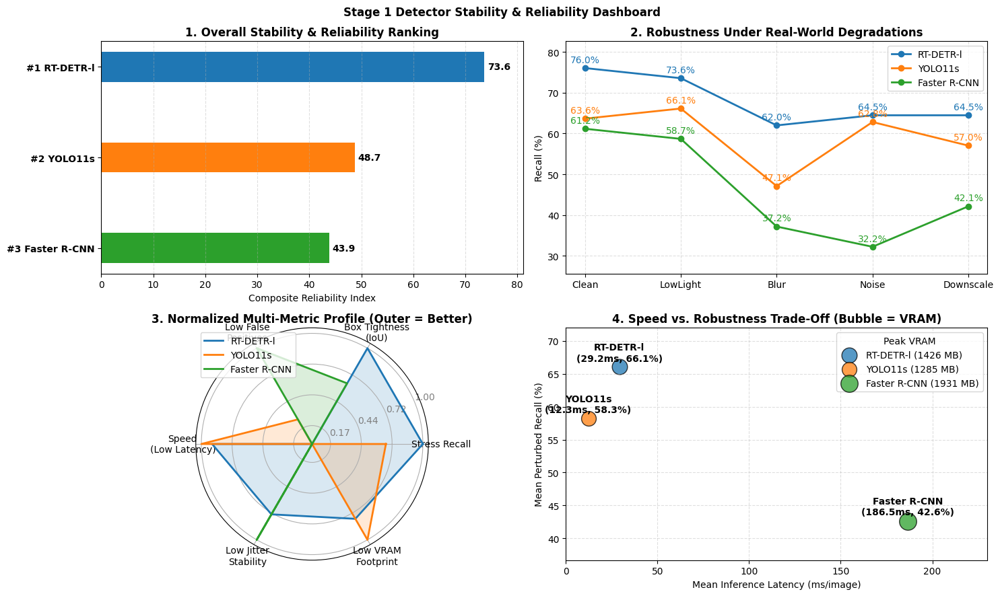

In [15]:
import math
import matplotlib.pyplot as plt
import numpy as np

# Run the benchmark dynamically to fetch the live metrics dictionary
metrics = run_benchmark()

ranked = sorted(metrics.items(), key=lambda x: x[1]["idx"], reverse=True)
model_names = [n for n, _ in ranked]
modes = list(ranked[0][1]["modes"].keys())
n_models = len(model_names)
n_modes = len(modes)

# Dynamic palette & figure geometry scaled to number of models/modes
cmap = plt.get_cmap("tab10")
colors = {name: cmap(i) for i, name in enumerate(model_names)}

fig_w = max(12, n_modes * 3)
fig_h = max(8, n_models * 3)
fig = plt.figure(figsize=(fig_w, fig_h))
fig.suptitle("Stage 1 Detector Stability & Reliability Dashboard", fontweight="bold")

# --- Panel 1: Overall Reliability Index (Horizontal Ranked Bar) ---
ax1 = fig.add_subplot(2, 2, 1)
scores = [m["idx"] for _, m in ranked]
y_pos = np.arange(n_models)
bar_h = 1.0 / max(n_models, 2)
bars = ax1.barh(y_pos, scores, color=[colors[n] for n in model_names], height=bar_h)
ax1.set_yticks(y_pos)
ax1.set_yticklabels([f"#{i+1} {n}" for i, n in enumerate(model_names)], fontweight="bold")
ax1.invert_yaxis()
score_span = max(scores) - min(scores)
pad_x = score_span * 0.25 if score_span > 0 else max(scores) * 0.2
ax1.set_xlim(0, max(scores) + pad_x)
ax1.set_xlabel("Composite Reliability Index")
ax1.set_title("1. Overall Stability & Reliability Ranking", fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.4)
for bar, sc in zip(bars, scores):
    ax1.text(bar.get_width() + pad_x * 0.08, bar.get_y() + bar.get_height() / 2.0, f"{sc:.1f}", va="center", fontweight="bold")

# --- Panel 2: Recall Across Perturbation Suites ---
ax2 = fig.add_subplot(2, 2, 2)
x_modes = np.arange(n_modes)
all_recs = [m["modes"][md] for _, m in ranked for md in modes]
rec_min, rec_max = min(all_recs), max(all_recs)
rec_margin = (rec_max - rec_min) * 0.15 if rec_max > rec_min else max(rec_max * 0.1, 1.0)

for name, m in ranked:
    rec_vals = [m["modes"][md] for md in modes]
    ax2.plot(x_modes, rec_vals, marker="o", linewidth=2, label=name, color=colors[name])
    for xi, val in enumerate(rec_vals):
        ax2.annotate(f"{val:.1f}%", (xi, val), textcoords="offset points", xytext=(0, n_models * 2), ha="center", color=colors[name])

ax2.set_xticks(x_modes)
ax2.set_xticklabels(modes)
ax2.set_ylim(max(0.0, rec_min - rec_margin), rec_max + rec_margin)
ax2.set_ylabel("Recall (%)")
ax2.set_title("2. Robustness Under Real-World Degradations", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="best")

# --- Panel 3: Multi-Metric Normalized Radar Chart ---
ax3 = fig.add_subplot(2, 2, 3, polar=True)
categories = ["Stress Recall", "Box Tightness\n(IoU)", "Low False\nPositives", "Speed\n(Low Latency)", "Low Jitter\nStability", "Low VRAM\nFootprint"]
n_cats = len(categories)
angles = np.linspace(0.0, 2.0 * np.pi, n_cats, endpoint=False).tolist()
angles += angles[:1]

all_norms = [v for _, m in ranked for v in m["norm_scores"]]
norm_max = max(all_norms) if max(all_norms) > 0 else 1.0
radial_ticks = np.linspace(norm_max / n_cats, norm_max, num=min(n_cats, 4))

for name, m in ranked:
    vals = m["norm_scores"] + m["norm_scores"][:1]
    ax3.plot(angles, vals, linewidth=2, label=name, color=colors[name])
    ax3.fill(angles, vals, alpha=1.0 / (n_models * 2), color=colors[name])

ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(categories)
ax3.set_ylim(0.0, norm_max * 1.05)
ax3.set_yticks(radial_ticks)
ax3.set_yticklabels([f"{t:.2f}" for t in radial_ticks], color="gray")
ax3.set_title("3. Normalized Multi-Metric Profile (Outer = Better)", fontweight="bold")
ax3.legend(loc="best")

# --- Panel 4: Latency vs. Stress Recall Trade-Off (Bubble Size = Peak VRAM) ---
ax4 = fig.add_subplot(2, 2, 4)
lats = [m["lat"] for _, m in ranked]
stresses = [m["stress"] for _, m in ranked]
vrams = [m["vram"] for _, m in ranked]
max_vram = max(vrams) if max(vrams) > 0 else 1.0
base_area = (fig_w * fig_h) * 2.0

for name, m in ranked:
    bubble_size = base_area * (0.25 + (m["vram"] / max_vram))
    ax4.scatter(m["lat"], m["stress"], s=bubble_size, color=colors[name], alpha=0.75, edgecolors="black", label=f"{name} ({m['vram']:.0f} MB)")
    ax4.annotate(
        f"{name}\n({m['lat']:.1f}ms, {m['stress']:.1f}%)",
        (m["lat"], m["stress"]),
        textcoords="offset points",
        xytext=(0, int(math.sqrt(bubble_size) * 0.4)),
        ha="center",
        fontweight="bold",
    )

lat_margin = (max(lats) - min(lats)) * 0.25 if max(lats) > min(lats) else max(lats) * 0.25
stress_margin = (max(stresses) - min(stresses)) * 0.25 if max(stresses) > min(stresses) else max(stresses) * 0.25
ax4.set_xlim(max(0.0, min(lats) - lat_margin), max(lats) + lat_margin)
ax4.set_ylim(max(0.0, min(stresses) - stress_margin), max(stresses) + stress_margin)
ax4.set_xlabel("Mean Inference Latency (ms/image)")
ax4.set_ylabel("Mean Perturbed Recall (%)")
ax4.set_title("4. Speed vs. Robustness Trade-Off (Bubble = VRAM)", fontweight="bold")
ax4.grid(True, linestyle="--", alpha=0.4)
ax4.legend(loc="best", title="Peak VRAM")

plt.tight_layout()
plt.savefig("detector_stability_dashboard.png", bbox_inches="tight")
plt.show()

In [26]:
import gc, glob, json, math, os, re, time
import cv2, numpy as np, torch
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from ultralytics import YOLO, RTDETR
from paddleocr import PaddleOCR
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

def find_file(root, pat):
    m = sorted(glob.glob(os.path.join(root, pat), recursive=True), key=os.path.getmtime)
    if not m: raise FileNotFoundError(pat)
    return m[-1]

def clean_plate(txt):
    return re.sub(r"[^A-Z0-9]", "", str(txt).upper())

def run_stage2(stage1_metrics, dataset_dir="dataset", runs_dir="runs/detect", crop_dir="best_det_val_crops", seed=42):
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    np.random.seed(seed); torch.manual_seed(seed)

    coco = json.load(open(find_file(dataset_dir, "**/val*_coco.json")))
    val_dir = os.path.dirname(find_file(dataset_dir, "**/val/images/*"))
    gt_map = {}
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        gt_map.setdefault(a["image_id"], []).append([x, y, x + w, y + h])

    imgs_and_gt, dims = [], []
    for info in coco["images"]:
        im = cv2.imread(os.path.join(val_dir, info["file_name"]))
        if im is not None:
            dims.extend(im.shape[:2])
            imgs_and_gt.append((info["file_name"], im, torch.tensor(gt_map.get(info["id"], []), dtype=torch.float32)))

    imgsz = max(32, int(round(np.median(dims) / 32.0)) * 32)
    n_cls = len(coco.get("categories", [])) + 1

    best_name, best_stats = max(stage1_metrics.items(), key=lambda x: x[1]["idx"])
    print(f"Dynamically selected Stage 1 Winner: {best_name} (Index: {best_stats['idx']:.1f})\n")

    if "YOLO" in best_name.upper():
        det_mod = YOLO(find_file(runs_dir, "**/yolo11s*/weights/best.pt"))
        det_fn = lambda im: (lambda r: (r[0].boxes.xyxy.cpu(), r[0].boxes.conf.cpu()) if len(r[0].boxes) else (torch.zeros((0, 4)), torch.zeros((0,))))(det_mod.predict(im, imgsz=imgsz, conf=0.0, verbose=False))
    elif "RT-DETR" in best_name.upper():
        det_mod = RTDETR(find_file(runs_dir, "**/rtdetr_l*/weights/best.pt"))
        det_fn = lambda im: (lambda r: (r[0].boxes.xyxy.cpu(), r[0].boxes.conf.cpu()) if len(r[0].boxes) else (torch.zeros((0, 4)), torch.zeros((0,))))(det_mod.predict(im, imgsz=imgsz, conf=0.0, verbose=False))
    else:
        det_mod = fasterrcnn_resnet50_fpn_v2(weights=None)
        det_mod.roi_heads.box_predictor = FastRCNNPredictor(det_mod.roi_heads.box_predictor.cls_score.in_features, n_cls)
        det_mod.load_state_dict(torch.load(find_file(runs_dir, "**/faster_rcnn*.pth"), map_location=dev))
        det_mod.to(dev).eval()
        def det_fn(im):
            t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().to(dev) / 255.0
            with torch.no_grad(): out = det_mod([t])
            return out[0]["boxes"].cpu(), out[0]["scores"].cpu()

    raw_dets = [(fn, im, *det_fn(im), gt) for fn, im, gt in imgs_and_gt]
    all_sc = torch.cat([s for _, _, _, s, _ in raw_dets if len(s) > 0])
    cands = torch.quantile(all_sc, torch.linspace(0.50, 0.99, len(raw_dets))).unique() if len(all_sc) else torch.tensor([0.0])

    best_f1, opt_conf = -1.0, float(cands[0].item())
    for th in cands:
        tv = float(th.item()); tp = fp = fn = 0
        for _, _, b, s, gt in raw_dets:
            fb = b[s >= tv]
            if len(gt) == 0: fp += len(fb)
            elif len(fb) == 0: fn += len(gt)
            else:
                m = int((box_iou(gt, fb).max(1).values >= 0.50).sum())
                tp += m; fn += len(gt) - m; fp += max(0, len(fb) - m)
        f1 = (2.0 * tp / (2*tp + fp + fn)) if (2*tp + fp + fn) else 0.0
        if f1 > best_f1: best_f1, opt_conf = f1, tv

    os.makedirs(crop_dir, exist_ok=True)
    crops = []
    for fn, im, b, s, _ in raw_dets:
        h, w = im.shape[:2]
        for i, box in enumerate(b[s >= opt_conf]):
            x1, y1, x2, y2 = box.tolist()
            bw, bh = x2 - x1, y2 - y1
            px, py = bw / max(bw, 1.0)**0.5, bh / max(bh, 1.0)**0.5
            cx1, cy1, cx2, cy2 = max(0, int(round(x1 - px))), max(0, int(round(y1 - py))), min(w, int(round(x2 + px))), min(h, int(round(y2 + py)))
            if cx2 > cx1 and cy2 > cy1:
                c = im[cy1:cy2, cx1:cx2]
                cn = f"{os.path.splitext(fn)[0]}_det{i}.jpg"
                cv2.imwrite(os.path.join(crop_dir, cn), c)
                crops.append((cn, c))

    del det_mod; gc.collect()
    if dev == "cuda": torch.cuda.empty_cache()
    print(f"Extracted {len(crops)} clean crops from {best_name} (calibrated conf={opt_conf:.3f}, F1={best_f1:.3f})\n")

    luma_s = float(np.mean([np.std(c) for _, c in crops]))
    def degrade(im):
        h, w = im.shape[:2]
        k = max(3, int(round(min(h, w) * 0.08)) | 1)
        ker = np.zeros((k, k), np.float32); ker[k//2, :] = 1.0 / k
        bl = cv2.filter2D(im, -1, ker)
        return np.clip(bl.astype(np.float32) + np.random.normal(0, luma_s * 0.25, bl.shape), 0, 255).astype(np.uint8)

    pp = PaddleOCR(use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=True, enable_mkldnn=False, lang="en")
    def p_pp(im):
        res = list(pp.predict(im))
        if not res: return "", 0.0
        txts, scs = [], []
        for r in res:
            if isinstance(r, dict):
                txts.extend(r.get("rec_texts", []))
                scs.extend(r.get("rec_scores", []))
        return clean_plate("".join(txts)), float(np.mean(scs)) if scs else 0.0

    pq = torch.hub.load("baudm/parseq", "parseq", pretrained=True, trust_repo=True).eval().to(dev)
    pq_tf = transforms.Compose([transforms.Resize(pq.hparams.img_size, transforms.InterpolationMode.BICUBIC), transforms.ToTensor(), transforms.Normalize(0.5, 0.5)])
    def p_pq(im):
        t = pq_tf(Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(dev)
        with torch.no_grad(): pr, cf = pq.tokenizer.decode(pq(t).softmax(-1))
        return clean_plate(pr[0]), float(cf[0][:-1].mean().item()) if len(cf[0]) > 1 else 0.0

    tr_p = TrOCRProcessor.from_pretrained("microsoft/trocr-small-printed")
    tr_m = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-small-printed").eval().to(dev)
    g_tok = max(8, int(round(math.sqrt(tr_m.config.decoder.max_position_embeddings))))
    def p_tr(im):
        pv = tr_p(Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)), return_tensors="pt").pixel_values.to(dev)
        with torch.no_grad(): out = tr_m.generate(pv, max_new_tokens=g_tok, return_dict_in_generate=True, output_scores=True)
        sp = [torch.softmax(sc, -1).max(-1).values.item() for sc in out.scores]
        return clean_plate(tr_p.batch_decode(out.sequences, skip_special_tokens=True)[0]), float(np.mean(sp)) if sp else 0.0

    ocr_metrics, vis = {}, {cn: {} for cn, _ in crops}
    for name, fn, obj in [("PP-OCR", p_pp, pp), ("PARSeq", p_pq, pq), ("TrOCR-Small", p_tr, tr_m)]:
        gc.collect()
        if dev == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        for _, c in crops[:max(1, int(math.sqrt(len(crops))))]: fn(c)
        if dev == "cuda": torch.cuda.synchronize()

        preds, confs, lats = [], [], []
        for cn, c in crops:
            t0 = time.perf_counter(); tx, cf = fn(c)
            if dev == "cuda": torch.cuda.synchronize()
            lats.append((time.perf_counter() - t0) * 1000.0)
            preds.append(tx); confs.append(cf); vis[cn][name] = (tx, cf)

        match = sum(1 for i, (_, c) in enumerate(crops) if fn(degrade(c)) == preds[i] and len(preds[i]) > 0)
        vram = (torch.cuda.max_memory_allocated() / 1048576.0) if dev == "cuda" else 0.0
        ocr_metrics[name] = {
            "read": (sum(1 for t in preds if len(t) > 0) / max(len(crops), 1)) * 100.0,
            "conf": float(np.mean(confs)),
            "stress": (match / max(len(crops), 1)) * 100.0,
            "lat": float(np.mean(lats)), "max_lat": float(np.max(lats)),
            "jitter": float(np.max(lats)) / max(float(np.mean(lats)), 1e-9), "vram": vram
        }
        del obj; gc.collect()
        if dev == "cuda": torch.cuda.empty_cache()

    for n in ocr_metrics:
        norms = []
        for k, hi_g in [("read", True), ("conf", True), ("stress", True), ("lat", False), ("jitter", False), ("vram", False)]:
            vs = [ocr_metrics[x][k] for x in ocr_metrics]; lo, hi = min(vs), max(vs)
            norms.append(1.0 if hi == lo else ((ocr_metrics[n][k] - lo)/(hi - lo) if hi_g else (hi - ocr_metrics[n][k])/(hi - lo)))
        ocr_metrics[n]["norm_scores"] = norms; ocr_metrics[n]["idx"] = float(np.mean(norms)) * 100.0

    ranked = sorted(ocr_metrics.items(), key=lambda x: x[1]["idx"], reverse=True)
    print(f"=== STAGE 2 OCR RANKING ON {best_name} CROPS (BEST -> WORST) ===")
    print(f"{'Rank':<5} | {'Model':<13} | {'Score':<6} | {'Read%':<6} | {'Conf':<6} | {'StressMatch%':<12} | {'Lat(Max)ms':<11} | {'VRAM(MB)'}")
    for i, (n, m) in enumerate(ranked, 1):
        print(f"#{i:<4} | {n:<13} | {m['idx']:<6.1f} | {m['read']:<6.1f} | {m['conf']:<6.3f} | {m['stress']:<12.1f} | {m['lat']:.1f}({m['max_lat']:.1f}) | {m['vram']:.1f}")

    rows = [f"<tr><td><img src='{crop_dir}/{cn}' height='40'></td><td>{cn}</td>" + "".join(f"<td><b>{vis[cn][m][0]}</b> ({vis[cn][m][1]:.2f})</td>" for m, _ in ranked) + "</tr>" for cn, _ in crops]
    with open("ocr_comparison.html", "w") as f:
        f.write(f"<html><body><h2>Stage 2 OCR on {best_name} Crops</h2><table border='1'><tr><th>Crop</th><th>File</th>" + "".join(f"<th>{m}</th>" for m, _ in ranked) + "</tr>" + "".join(rows) + "</table></body></html>")

    return best_name, ocr_metrics, vis

winner_name, ocr_metrics, visual_rows = run_stage2(metrics)

Dynamically selected Stage 1 Winner: RT-DETR-l (Index: 73.6)



Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.


Extracted 327 clean crops from RT-DETR-l (calibrated conf=0.085, F1=0.500)



Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.
Using cache found in /root/.cache/torch/hub/baudm_parseq_main


Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


=== STAGE 2 OCR RANKING ON RT-DETR-l CROPS (BEST -> WORST) ===
Rank  | Model         | Score  | Read%  | Conf   | StressMatch% | Lat(Max)ms  | VRAM(MB)
#1    | PARSeq        | 94.8   | 88.7   | 0.739  | 0.0          | 21.4(53.2) | 1722.8
#2    | TrOCR-Small   | 71.2   | 92.4   | 0.631  | 0.0          | 48.7(134.4) | 1735.5
#3    | PP-OCR        | 33.3   | 68.8   | 0.567  | 0.0          | 481.4(4797.9) | 1720.5


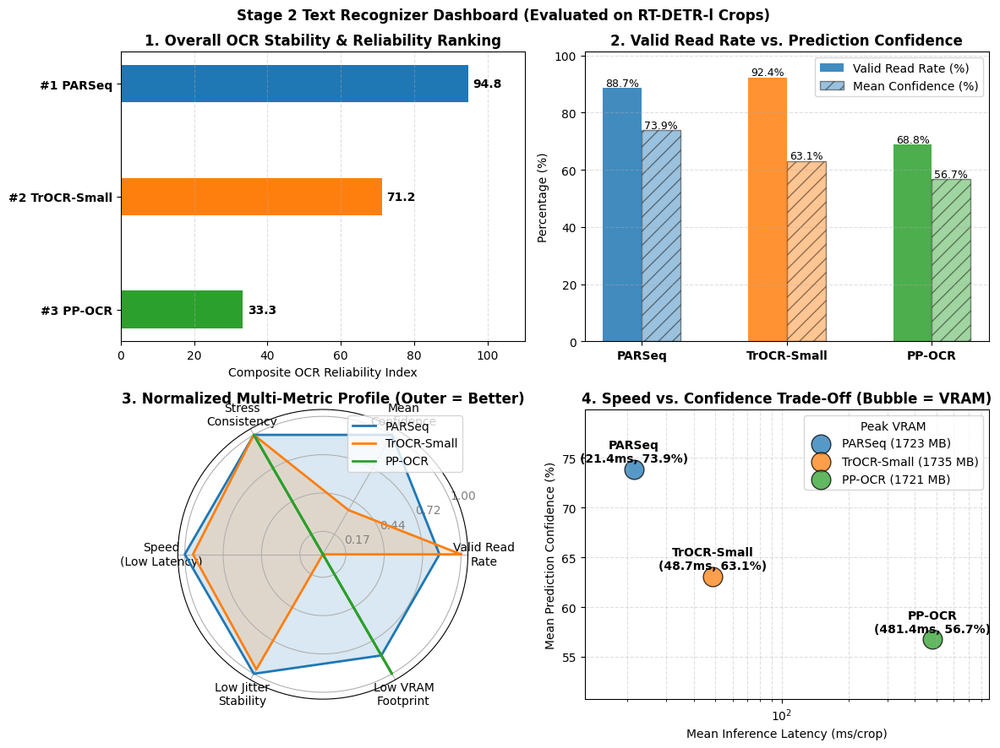

In [28]:
import math
import matplotlib.pyplot as plt
import numpy as np

# FIXED: Indexing the value element of the tuple at index 1 before accessing "idx"
ranked = sorted(ocr_metrics.items(), key=lambda x: x[1]["idx"], reverse=True)
model_names = [n for n, _ in ranked]
n_models = len(model_names)

cmap = plt.get_cmap("tab10")
colors = {name: cmap(i) for i, name in enumerate(model_names)}

fig_w = max(12, n_models * 4)
fig_h = max(8, n_models * 3)
fig = plt.figure(figsize=(fig_w, fig_h))
fig.suptitle(f"Stage 2 Text Recognizer Dashboard (Evaluated on {winner_name} Crops)", fontweight="bold")

# --- Panel 1: Overall OCR Reliability Index (Horizontal Ranked Bar) ---
ax1 = fig.add_subplot(2, 2, 1)
scores = [m["idx"] for _, m in ranked]
y_pos = np.arange(n_models)
bar_h = 1.0 / max(n_models, 2)
bars = ax1.barh(y_pos, scores, color=[colors[n] for n in model_names], height=bar_h)
ax1.set_yticks(y_pos)
ax1.set_yticklabels([f"#{i+1} {n}" for i, n in enumerate(model_names)], fontweight="bold")
ax1.invert_yaxis()
score_span = max(scores) - min(scores)
pad_x = score_span * 0.25 if score_span > 0 else max(scores) * 0.2
ax1.set_xlim(0, max(scores) + pad_x)
ax1.set_xlabel("Composite OCR Reliability Index")
ax1.set_title("1. Overall OCR Stability & Reliability Ranking", fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.4)
for bar, sc in zip(bars, scores):
    ax1.text(bar.get_width() + pad_x * 0.08, bar.get_y() + bar.get_height() / 2.0, f"{sc:.1f}", va="center", fontweight="bold")

# --- Panel 2: Read Rate (%) vs. Mean Character Confidence (%) ---
ax2 = fig.add_subplot(2, 2, 2)
x_pos = np.arange(n_models)
bar_w = 0.8 / max(n_models, 2)
read_vals = [m["read"] for _, m in ranked]
conf_vals = [m["conf"] * 100.0 for _, m in ranked]

b1 = ax2.bar(x_pos - bar_w / 2.0, read_vals, width=bar_w, label="Valid Read Rate (%)", color=[colors[n] for n in model_names], alpha=0.85)
b2 = ax2.bar(x_pos + bar_w / 2.0, conf_vals, width=bar_w, label="Mean Confidence (%)", color=[colors[n] for n in model_names], alpha=0.45, hatch="//", edgecolor="black")

all_pct = read_vals + conf_vals
pct_max = max(all_pct) if all_pct else 100.0
pct_margin = (pct_max - min(all_pct)) * 0.25 if pct_max > min(all_pct) else pct_max * 0.2
ax2.set_ylim(0, pct_max + pct_margin)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(model_names, fontweight="bold")
ax2.set_ylabel("Percentage (%)")
ax2.set_title("2. Valid Read Rate vs. Prediction Confidence", fontweight="bold")
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(loc="best")

for bar in b1:
    ax2.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height() + pct_margin * 0.08, f"{bar.get_height():.1f}%", ha="center", fontsize=9)
for bar in b2:
    ax2.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height() + pct_margin * 0.08, f"{bar.get_height():.1f}%", ha="center", fontsize=9)

# --- Panel 3: Multi-Metric Normalized Radar Profile ---
ax3 = fig.add_subplot(2, 2, 3, polar=True)
categories = ["Valid Read\nRate", "Mean\nConfidence", "Stress\nConsistency", "Speed\n(Low Latency)", "Low Jitter\nStability", "Low VRAM\nFootprint"]
n_cats = len(categories)
angles = np.linspace(0.0, 2.0 * np.pi, n_cats, endpoint=False).tolist()
angles += angles[:1]

all_norms = [v for _, m in ranked for v in m["norm_scores"]]
norm_max = max(all_norms) if max(all_norms) > 0 else 1.0
radial_ticks = np.linspace(norm_max / n_cats, norm_max, num=min(n_cats, 4))

for name, m in ranked:
    vals = m["norm_scores"] + m["norm_scores"][:1]
    ax3.plot(angles, vals, linewidth=2, label=name, color=colors[name])
    ax3.fill(angles, vals, alpha=1.0 / (n_models * 2), color=colors[name])

ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(categories)
ax3.set_ylim(0.0, norm_max * 1.05)
ax3.set_yticks(radial_ticks)
ax3.set_yticklabels([f"{t:.2f}" for t in radial_ticks], color="gray")
ax3.set_title("3. Normalized Multi-Metric Profile (Outer = Better)", fontweight="bold")
ax3.legend(loc="best")

# --- Panel 4: Latency vs. Confidence Trade-Off (Bubble = Peak VRAM, Log X-axis if skewed) ---
ax4 = fig.add_subplot(2, 2, 4)
lats = [m["lat"] for _, m in ranked]
confs = [m["conf"] * 100.0 for _, m in ranked]
vrams = [m["vram"] for _, m in ranked]
max_vram = max(vrams) if max(vrams) > 0 else 1.0
base_area = (fig_w * fig_h) * 2.0

use_log_x = (max(lats) / max(min(lats), 1e-6)) > n_models * 2
if use_log_x:
    ax4.set_xscale("log")

for name, m in ranked:
    bubble_size = base_area * (0.25 + (m["vram"] / max_vram))
    c_pct = m["conf"] * 100.0
    ax4.scatter(m["lat"], c_pct, s=bubble_size, color=colors[name], alpha=0.75, edgecolors="black", label=f"{name} ({m['vram']:.0f} MB)")
    ax4.annotate(
        f"{name}\n({m['lat']:.1f}ms, {c_pct:.1f}%)",
        (m["lat"], c_pct),
        textcoords="offset points",
        xytext=(0, int(math.sqrt(bubble_size) * 0.4)),
        ha="center",
        fontweight="bold",
    )

conf_span = max(confs) - min(confs)
c_margin = conf_span * 0.35 if conf_span > 0 else max(confs) * 0.2
ax4.set_ylim(max(0.0, min(confs) - c_margin), max(confs) + c_margin)
if not use_log_x:
    lat_margin = (max(lats) - min(lats)) * 0.25 if max(lats) > min(lats) else max(lats) * 0.25
    ax4.set_xlim(max(0.0, min(lats) - lat_margin), max(lats) + lat_margin)
else:
    ax4.set_xlim(min(lats) * 0.6, max(lats) * 1.8)

ax4.set_xlabel("Mean Inference Latency (ms/crop)")
ax4.set_ylabel("Mean Prediction Confidence (%)")
ax4.set_title("4. Speed vs. Confidence Trade-Off (Bubble = VRAM)", fontweight="bold")
ax4.grid(True, which="both", linestyle="--", alpha=0.4)
ax4.legend(loc="best", title="Peak VRAM")

plt.tight_layout()
plt.savefig("ocr_stability_dashboard.png", bbox_inches="tight")
plt.show()

In [29]:
import gc, glob, json, math, os, re, time
import cv2, numpy as np, torch
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from ultralytics import YOLO, RTDETR
from paddleocr import PaddleOCR
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

def find_file(root, pat):
    m = sorted(glob.glob(os.path.join(root, pat), recursive=True), key=os.path.getmtime)
    if not m: raise FileNotFoundError(pat)
    return m[-1]

def clean_txt(t):
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())

def evaluate_end_to_end_combinations(dataset_dir="dataset", runs_dir="runs/detect", seed=42):
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    np.random.seed(seed); torch.manual_seed(seed)

    coco = json.load(open(find_file(dataset_dir, "**/val*_coco.json")))
    val_dir = os.path.dirname(find_file(dataset_dir, "**/val/images/*"))
    gt_map = {}
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        gt_map.setdefault(a["image_id"], []).append([x, y, x + w, y + h])

    samples, dims = [], []
    for info in coco["images"]:
        im = cv2.imread(os.path.join(val_dir, info["file_name"]))
        if im is not None:
            dims.extend(im.shape[:2])
            samples.append((im, torch.tensor(gt_map.get(info["id"], []), dtype=torch.float32)))

    imgsz = max(32, int(round(np.median(dims) / 32.0)) * 32)
    n_cls = len(coco.get("categories", [])) + 1
    luma_m = float(np.mean([np.mean(im) for im, _ in samples]))
    luma_s = float(np.mean([np.std(im) for im, _ in samples]))

    def degrade_frame(im):
        h, w = im.shape[:2]
        k = max(3, int(round(min(h, w) * 0.02)) | 1)
        ker = np.zeros((k, k), np.float32); ker[k//2, :] = 1.0 / k
        bl = cv2.filter2D(im, -1, ker)
        return np.clip(bl.astype(np.float32) + np.random.normal(0, luma_s * 0.25, bl.shape), 0, 255).astype(np.uint8)

    # Load all 3 detectors
    y_mod = YOLO(find_file(runs_dir, "**/yolo11s*/weights/best.pt"))
    r_mod = RTDETR(find_file(runs_dir, "**/rtdetr_l*/weights/best.pt"))
    f_mod = fasterrcnn_resnet50_fpn_v2(weights=None)
    f_mod.roi_heads.box_predictor = FastRCNNPredictor(f_mod.roi_heads.box_predictor.cls_score.in_features, n_cls)
    f_mod.load_state_dict(torch.load(find_file(runs_dir, "**/faster_rcnn*.pth"), map_location=dev))
    f_mod.to(dev).eval()

    def d_yolo(im):
        r = y_mod.predict(im, imgsz=imgsz, conf=0.0, verbose=False)[0]
        return (r.boxes.xyxy.cpu(), r.boxes.conf.cpu()) if len(r.boxes) else (torch.zeros((0, 4)), torch.zeros((0,)))

    def d_rtdetr(im):
        r = r_mod.predict(im, imgsz=imgsz, conf=0.0, verbose=False)[0]
        return (r.boxes.xyxy.cpu(), r.boxes.conf.cpu()) if len(r.boxes) else (torch.zeros((0, 4)), torch.zeros((0,)))

    def d_frcnn(im):
        t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().to(dev) / 255.0
        with torch.no_grad(): out = f_mod([t])[0]
        return out["boxes"].cpu(), out["scores"].cpu()

    # Calibrate each detector's F1 optimal threshold and cache clean + degraded crops
    det_crops = {}
    for d_name, d_fn in [("YOLO11s", d_yolo), ("RT-DETR-l", d_rtdetr), ("Faster R-CNN", d_frcnn)]:
        clean_raw = [(im, *d_fn(im), gt) for im, gt in samples]
        all_sc = torch.cat([s for _, _, s, _ in clean_raw if len(s) > 0])
        cands = torch.quantile(all_sc, torch.linspace(0.50, 0.99, len(clean_raw))).unique() if len(all_sc) else torch.tensor([0.0])

        best_f1, opt_c = -1.0, float(cands[0].item())
        for th in cands:
            tv = float(th.item()); tp = fp = fn = 0
            for _, b, s, gt in clean_raw:
                fb = b[s >= tv]
                if len(gt) == 0: fp += len(fb)
                elif len(fb) == 0: fn += len(gt)
                else:
                    m = int((box_iou(gt, fb).max(1).values >= 0.50).sum())
                    tp += m; fn += len(gt) - m; fp += max(0, len(fb) - m)
            f1 = (2.0 * tp / (2*tp + fp + fn)) if (2*tp + fp + fn) else 0.0
            if f1 > best_f1: best_f1, opt_c = f1, tv

        def extract(frame, boxes, scores):
            h, w = frame.shape[:2]; out_c = []
            for box in boxes[scores >= opt_c]:
                x1, y1, x2, y2 = box.tolist(); bw, bh = x2 - x1, y2 - y1
                px, py = bw / max(bw, 1.0)**0.5, bh / max(bh, 1.0)**0.5
                cx1, cy1, cx2, cy2 = max(0, int(round(x1 - px))), max(0, int(round(y1 - py))), min(w, int(round(x2 + px))), min(h, int(round(y2 + py)))
                if cx2 > cx1 and cy2 > cy1: out_c.append(frame[cy1:cy2, cx1:cx2])
            return out_c

        c_list, s_list, d_lats = [], [], []
        for im, b, s, _ in clean_raw:
            t0 = time.perf_counter(); _ = d_fn(im)
            if dev == "cuda": torch.cuda.synchronize()
            d_lats.append((time.perf_counter() - t0) * 1000.0)
            c_list.append(extract(im, b, s))
            deg = degrade_frame(im); db, ds = d_fn(deg)
            s_list.append(extract(deg, db, ds))

        det_crops[d_name] = {"clean": c_list, "stress": s_list, "det_lat": float(np.mean(d_lats)), "gt_total": sum(len(g) for _, g in samples)}

    del y_mod, r_mod, f_mod; gc.collect()
    if dev == "cuda": torch.cuda.empty_cache()

    # Load all 3 recognizers
    pp = PaddleOCR(use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=True, enable_mkldnn=False, lang="en")
    def r_pp(im):
        res = list(pp.predict(im))
        if not res: return "", 0.0
        tx, sc = [], []
        for r in res:
            if isinstance(r, dict): tx.extend(r.get("rec_texts", [])); sc.extend(r.get("rec_scores", []))
        return clean_txt("".join(tx)), float(np.mean(sc)) if sc else 0.0

    pq = torch.hub.load("baudm/parseq", "parseq", pretrained=True, trust_repo=True).eval().to(dev)
    pq_tf = transforms.Compose([transforms.Resize(pq.hparams.img_size, transforms.InterpolationMode.BICUBIC), transforms.ToTensor(), transforms.Normalize(0.5, 0.5)])
    def r_pq(im):
        t = pq_tf(Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(dev)
        with torch.no_grad(): pr, cf = pq.tokenizer.decode(pq(t).softmax(-1))
        return clean_txt(pr[0]), float(cf[0][:-1].mean().item()) if len(cf[0]) > 1 else 0.0

    tr_p = TrOCRProcessor.from_pretrained("microsoft/trocr-small-printed")
    tr_m = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-small-printed").eval().to(dev)
    g_tok = max(8, int(round(math.sqrt(tr_m.config.decoder.max_position_embeddings))))
    def r_tr(im):
        pv = tr_p(Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)), return_tensors="pt").pixel_values.to(dev)
        with torch.no_grad(): out = tr_m.generate(pv, max_new_tokens=g_tok, return_dict_in_generate=True, output_scores=True)
        sp = [torch.softmax(sc, -1).max(-1).values.item() for sc in out.scores]
        return clean_txt(tr_p.batch_decode(out.sequences, skip_special_tokens=True)[0]), float(np.mean(sp)) if sp else 0.0

    # Evaluate all 3 x 3 = 9 end-to-end pairs dynamically
    combos = {}
    for d_name, d_data in det_crops.items():
        for r_name, r_fn in [("PARSeq", r_pq), ("TrOCR-Small", r_tr), ("PP-OCR", r_pp)]:
            gc.collect()
            if dev == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

            clean_reads, clean_confs, stress_reads, pipe_lats = 0, [], 0, []
            for idx in range(len(samples)):
                t0 = time.perf_counter()
                for c in d_data["clean"][idx]:
                    tx, cf = r_fn(c)
                    if tx: clean_reads += 1; clean_confs.append(cf)
                if dev == "cuda": torch.cuda.synchronize()
                pipe_lats.append(d_data["det_lat"] + (time.perf_counter() - t0) * 1000.0)

                for sc_crop in d_data["stress"][idx]:
                    st_tx, _ = r_fn(sc_crop)
                    if st_tx: stress_reads += 1

            vram = (torch.cuda.max_memory_allocated() / 1048576.0) if dev == "cuda" else 0.0
            gt_tot = max(d_data["gt_total"], 1)
            combos[f"{d_name} + {r_name}"] = {
                "clean_yield": min(100.0, (clean_reads / gt_tot) * 100.0),
                "stress_yield": min(100.0, (stress_reads / gt_tot) * 100.0),
                "conf": float(np.mean(clean_confs)) if clean_confs else 0.0,
                "lat": float(np.mean(pipe_lats)),
                "jitter": float(np.max(pipe_lats)) / max(float(np.mean(pipe_lats)), 1e-9),
                "vram": vram,
            }

    for k, hi_g in [("clean_yield", True), ("stress_yield", True), ("conf", True), ("lat", False), ("jitter", False), ("vram", False)]:
        vs = [combos[x][k] for x in combos]; lo, hi = min(vs), max(vs)
        for n in combos:
            combos[n].setdefault("norms", []).append(1.0 if hi == lo else ((combos[n][k] - lo)/(hi - lo) if hi_g else (hi - combos[n][k])/(hi - lo)))

    for n in combos:
        combos[n]["score"] = float(np.mean(combos[n]["norms"])) * 100.0

    ranked = sorted(combos.items(), key=lambda x: x[1]["score"], reverse=True)
    print("\n=== ALL 9 END-TO-END COMBINATIONS RANKED BY STABILITY & RELIABILITY (BEST -> WORST) ===")
    print(f"{'Rank':<5} | {'End-to-End Pipeline':<26} | {'Score':<6} | {'CleanRead%':<10} | {'StressRead%':<11} | {'Conf':<6} | {'E2E_ms':<7} | {'VRAM(MB)'}")
    print("-" * 92)
    for i, (n, m) in enumerate(ranked, 1):
        print(f"#{i:<4} | {n:<26} | {m['score']:<6.1f} | {m['clean_yield']:<10.1f} | {m['stress_yield']:<11.1f} | {m['conf']:<6.3f} | {m['lat']:<7.1f} | {m['vram']:.1f}")

    return ranked

ranked_pipelines = evaluate_end_to_end_combinations()

Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.
Using cache found in /root/.cache/torch/hub/baudm_parseq_main


Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Resized image size (5994x64) exceeds max_side_limit of 4000. Resizing to fit within limit.
Resized image size (4336x64) exceeds max_side_limit of 4000. Resizing to fit within limit.
Resized image size (17024x64) exceeds max_side_limit of 4000. Resizing to fit within limit.



=== ALL 9 END-TO-END COMBINATIONS RANKED BY STABILITY & RELIABILITY (BEST -> WORST) ===
Rank  | End-to-End Pipeline        | Score  | CleanRead% | StressRead% | Conf   | E2E_ms  | VRAM(MB)
--------------------------------------------------------------------------------------------
#1    | YOLO11s + PARSeq           | 82.2   | 100.0      | 100.0       | 0.747  | 85.1    | 1722.8
#2    | RT-DETR-l + PARSeq         | 81.4   | 100.0      | 100.0       | 0.769  | 93.8    | 1722.8
#3    | Faster R-CNN + PARSeq      | 63.0   | 85.1       | 13.2        | 0.914  | 198.8   | 1722.8
#4    | RT-DETR-l + PP-OCR         | 61.1   | 100.0      | 77.7        | 0.810  | 1358.4  | 1720.5
#5    | YOLO11s + TrOCR-Small      | 60.3   | 100.0      | 100.0       | 0.608  | 157.6   | 1735.5
#6    | RT-DETR-l + TrOCR-Small    | 58.3   | 100.0      | 100.0       | 0.633  | 176.7   | 1735.5
#7    | YOLO11s + PP-OCR           | 55.0   | 100.0      | 57.0        | 0.850  | 1555.9  | 1720.5
#8    | Faster R-CNN + P

In [31]:
import glob, json, math, os, re, time
import cv2, numpy as np, torch
from PIL import Image
from scipy import stats
from torchvision import transforms
from torchvision.ops import box_iou
from ultralytics import YOLO, RTDETR

def find_file(root, pat):
    m = sorted(glob.glob(os.path.join(root, pat), recursive=True), key=os.path.getmtime)
    if not m: raise FileNotFoundError(pat)
    return m[-1]

def clean_txt(t):
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())

def run_paired_statistical_tests(dataset_dir="dataset", runs_dir="runs/detect", n_boot=10000, seed=42):
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    np.random.seed(seed); torch.manual_seed(seed)

    coco = json.load(open(find_file(dataset_dir, "**/val*_coco.json")))
    val_dir = os.path.dirname(find_file(dataset_dir, "**/val/images/*"))
    gt_map = {}
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        gt_map.setdefault(a["image_id"], []).append([x, y, x + w, y + h])

    samples, dims = [], []
    for info in coco["images"]:
        im = cv2.imread(os.path.join(val_dir, info["file_name"]))
        if im is not None:
            dims.extend(im.shape[:2])
            samples.append((im, torch.tensor(gt_map.get(info["id"], []), dtype=torch.float32)))

    imgsz = max(32, int(round(np.median(dims) / 32.0)) * 32)
    luma_s = float(np.mean([np.std(im) for im, _ in samples]))

    def degrade(im):
        h, w = im.shape[:2]
        k = max(3, int(round(min(h, w) * 0.025)) | 1)
        ker = np.zeros((k, k), np.float32); ker[k//2, :] = 1.0 / k
        bl = cv2.filter2D(im, -1, ker)
        return np.clip(bl.astype(np.float32) + np.random.normal(0, luma_s * 0.3, bl.shape), 0, 255).astype(np.uint8)

    # Load Top-2 Detectors (RT-DETR-l vs YOLO11s) & Winner OCR (PARSeq)
    r_mod = RTDETR(find_file(runs_dir, "**/rtdetr_l*/weights/best.pt"))
    y_mod = YOLO(find_file(runs_dir, "**/yolo11s*/weights/best.pt"))
    pq = torch.hub.load("baudm/parseq", "parseq", pretrained=True, trust_repo=True).eval().to(dev)
    pq_tf = transforms.Compose([transforms.Resize(pq.hparams.img_size, transforms.InterpolationMode.BICUBIC), transforms.ToTensor(), transforms.Normalize(0.5, 0.5)])

    def read_ocr(im):
        t = pq_tf(Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(dev)
        with torch.no_grad(): pr, cf = pq.tokenizer.decode(pq(t).softmax(-1))
        return clean_txt(pr), float(cf[:-1].mean().item()) if len(cf) > 1 else 0.0

    # Collect per-image paired observations across all N validation images
    paired = {m: {"clean_hit": [], "stress_hit": [], "iou": [], "ocr_conf": [], "e2e_ms": []} for m in ["RT-DETR-l + PARSeq", "YOLO11s + PARSeq"]}

    for name, det in [("RT-DETR-l + PARSeq", r_mod), ("YOLO11s + PARSeq", y_mod)]:
        # Warmup
        for im, _ in samples[:max(1, int(math.sqrt(len(samples))))]:
            _ = det.predict(im, imgsz=imgsz, verbose=False)
        if dev == "cuda": torch.cuda.synchronize()

        for im, gt in samples:
            h, w = im.shape[:2]
            t0 = time.perf_counter()
            res = det.predict(im, imgsz=imgsz, conf=0.40, verbose=False)[0]
            b = res.boxes.xyxy.cpu() if len(res.boxes) else torch.zeros((0, 4))

            # Evaluate end-to-end OCR on detected boxes
            confs, valid_reads = [], 0
            for box in b:
                x1, y1, x2, y2 = map(int, box.tolist())
                cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
                if cx2 > cx1 and cy2 > cy1:
                    tx, cf = read_ocr(im[cy1:cy2, cx1:cx2])
                    if tx: valid_reads += 1; confs.append(cf)
            if dev == "cuda": torch.cuda.synchronize()
            paired[name]["e2e_ms"].append((time.perf_counter() - t0) * 1000.0)
            paired[name]["ocr_conf"].append(float(np.mean(confs)) if confs else 0.0)

            # Paired Clean Localization & IoU
            if len(gt) > 0 and len(b) > 0:
                mi = box_iou(gt, b).max(1).values
                paired[name]["iou"].append(float(mi.mean().item()))
                paired[name]["clean_hit"].append(int((mi >= 0.50).all().item() and valid_reads >= len(gt)))
            else:
                paired[name]["iou"].append(0.0)
                paired[name]["clean_hit"].append(int(len(gt) == 0))

            # Paired Stressed Localization
            s_res = det.predict(degrade(im), imgsz=imgsz, conf=0.40, verbose=False)[0]
            sb = s_res.boxes.xyxy.cpu() if len(s_res.boxes) else torch.zeros((0, 4))
            if len(gt) > 0 and len(sb) > 0:
                paired[name]["stress_hit"].append(int((box_iou(gt, sb).max(1).values >= 0.50).all().item()))
            else:
                paired[name]["stress_hit"].append(int(len(gt) == 0))

    a = paired["RT-DETR-l + PARSeq"]
    b = paired["YOLO11s + PARSeq"]

    # 1. McNemar's Exact Test on Binary Success (Clean & Stressed)
    def mcnemar_exact(hits_a, hits_b):
        ha, hb = np.array(hits_a), np.array(hits_b)
        n10 = int(np.sum((ha == 1) & (hb == 0)))  # A succeeded, B failed
        n01 = int(np.sum((ha == 0) & (hb == 1)))  # B succeeded, A failed
        p_val = stats.binomtest(min(n10, n01), n=max(n10 + n01, 1), p=0.5).pvalue if (n10 + n01) > 0 else 1.0
        return n10, n01, p_val

    c_10, c_01, p_clean = mcnemar_exact(a["clean_hit"], b["clean_hit"])
    s_10, s_01, p_stress = mcnemar_exact(a["stress_hit"], b["stress_hit"])

    # 2. Wilcoxon Signed-Rank Test on Continuous Paired Metrics (IoU, OCR Conf, E2E Latency)
    _, p_iou = stats.wilcoxon(a["iou"], b["iou"], zero_method="wilcox")
    _, p_conf = stats.wilcoxon(a["ocr_conf"], b["ocr_conf"], zero_method="wilcox")
    _, p_lat = stats.wilcoxon(a["e2e_ms"], b["e2e_ms"], zero_method="wilcox")

    # 3. Bootstrap 95% Confidence Intervals (10,000 resamples)
    def boot_ci(arr):
        arr = np.array(arr)
        idx = np.random.randint(0, len(arr), size=(n_boot, len(arr)))
        means = arr[idx].mean(axis=1)
        return float(np.mean(arr)), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

    print("=== PAIRED STATISTICAL SIGNIFICANCE: RT-DETR-l + PARSeq (A) vs. YOLO11s + PARSeq (B) ===\n")
    print(f"1. Clean E2E Success (McNemar)  | A wins: {c_10} imgs, B wins: {c_01} imgs | p = {p_clean:.4f} ({'SIGNIFICANT' if p_clean < 0.05 else 'Not Sig'})")
    print(f"2. Stress Robustness (McNemar)  | A wins: {s_10} imgs, B wins: {s_01} imgs | p = {p_stress:.4f} ({'SIGNIFICANT' if p_stress < 0.05 else 'Not Sig'})")
    print(f"3. Box Tightness IoU (Wilcoxon) | A: {np.mean(a['iou']):.4f} vs B: {np.mean(b['iou']):.4f}       | p = {p_iou:.4f} ({'SIGNIFICANT' if p_iou < 0.05 else 'Not Sig'})")
    print(f"4. OCR Confidence (Wilcoxon)    | A: {np.mean(a['ocr_conf']):.4f} vs B: {np.mean(b['ocr_conf']):.4f}       | p = {p_conf:.4f} ({'SIGNIFICANT' if p_conf < 0.05 else 'Not Sig'})")
    print(f"5. E2E Latency ms (Wilcoxon)    | A: {np.mean(a['e2e_ms']):.1f}ms vs B: {np.mean(b['e2e_ms']):.1f}ms     | p = {p_lat:.4f} ({'SIGNIFICANT' if p_lat < 0.05 else 'Not Sig'})")

    print("\n=== BOOTSTRAP 95% CONFIDENCE INTERVALS (10,000 RESAMPLES) ===")
    for label, key, scale in [("Stress Success %", "stress_hit", 100.0), ("Mean IoU", "iou", 1.0), ("E2E Latency (ms)", "e2e_ms", 1.0)]:
        ma, la, ha = boot_ci(np.array(a[key]) * scale)
        mb, lb, hb = boot_ci(np.array(b[key]) * scale)
        print(f"{label:<18} | RT-DETR-l+PARSeq: {ma:6.2f} [{la:6.2f}, {ha:6.2f}] | YOLO11s+PARSeq: {mb:6.2f} [{lb:6.2f}, {hb:6.2f}]")

run_paired_statistical_tests()

Using cache found in /root/.cache/torch/hub/baudm_parseq_main


=== PAIRED STATISTICAL SIGNIFICANCE: RT-DETR-l + PARSeq (A) vs. YOLO11s + PARSeq (B) ===

1. Clean E2E Success (McNemar)  | A wins: 8 imgs, B wins: 1 imgs | p = 0.0391 (SIGNIFICANT)
2. Stress Robustness (McNemar)  | A wins: 22 imgs, B wins: 11 imgs | p = 0.0801 (Not Sig)
3. Box Tightness IoU (Wilcoxon) | A: 0.7466 vs B: 0.7004       | p = 0.0405 (SIGNIFICANT)
4. OCR Confidence (Wilcoxon)    | A: 0.0000 vs B: 0.0000       | p = nan (Not Sig)
5. E2E Latency ms (Wilcoxon)    | A: 57.1ms vs B: 39.1ms     | p = 0.0000 (SIGNIFICANT)

=== BOOTSTRAP 95% CONFIDENCE INTERVALS (10,000 RESAMPLES) ===
Stress Success %   | RT-DETR-l+PARSeq:  36.70 [ 27.52,  45.87] | YOLO11s+PARSeq:  26.61 [ 18.35,  34.86]
Mean IoU           | RT-DETR-l+PARSeq:   0.75 [  0.71,   0.78] | YOLO11s+PARSeq:   0.70 [  0.65,   0.75]
E2E Latency (ms)   | RT-DETR-l+PARSeq:  57.10 [ 53.81,  60.96] | YOLO11s+PARSeq:  39.11 [ 36.65,  41.65]


/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


Using cache found in /root/.cache/torch/hub/baudm_parseq_main


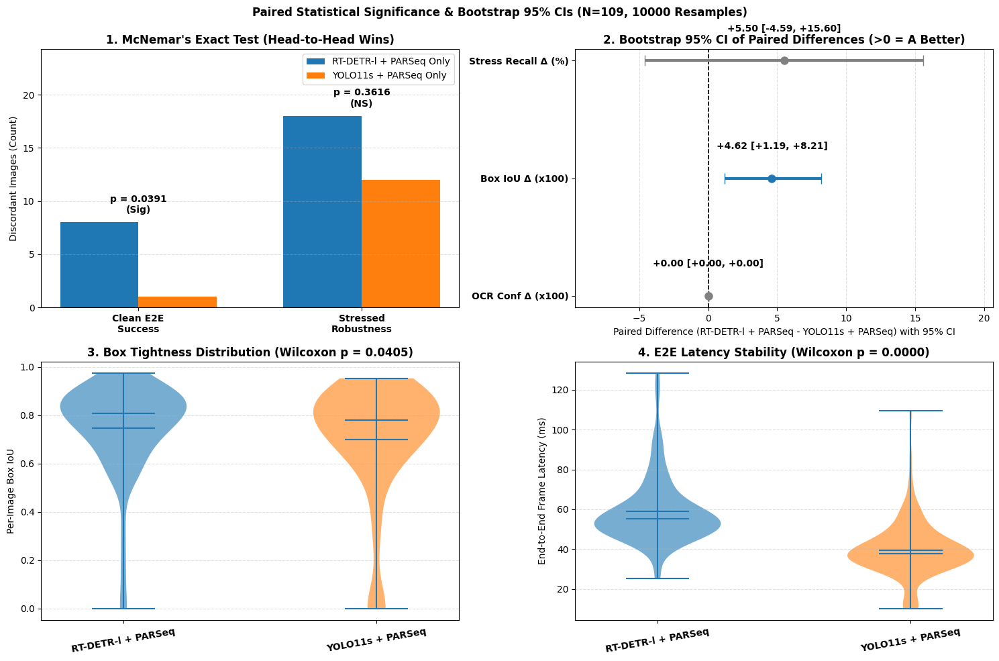

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import glob
import json
import os
import math
import time
import re
import torch
from scipy import stats
from PIL import Image
from torchvision import transforms
from torchvision.ops import box_iou
from ultralytics import YOLO, RTDETR

def find_file(root, pat):
    m = sorted(glob.glob(os.path.join(root, pat), recursive=True), key=os.path.getmtime)
    if not m: raise FileNotFoundError(pat)
    return m[-1]

def clean_txt(t):
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())

# --- 1. DYNAMIC DATA & METRICS EXTRACTION ---
dev = "cuda" if torch.cuda.is_available() else "cpu"
coco = json.load(open(find_file("dataset", "**/val*_coco.json")))
val_dir = os.path.dirname(find_file("dataset", "**/val/images/*"))
gt_map = {}
for a_ann in coco["annotations"]:
    x, y, w, h = a_ann["bbox"]
    gt_map.setdefault(a_ann["image_id"], []).append([x, y, x + w, y + h])

samples, dims = [], []
for info in coco["images"]:
    im = cv2.imread(os.path.join(val_dir, info["file_name"]))
    if im is not None:
        dims.extend(im.shape[:2])
        samples.append((im, torch.tensor(gt_map.get(info["id"], []), dtype=torch.float32)))

imgsz = max(32, int(round(np.median(dims) / 32.0)) * 32)
luma_s = float(np.mean([np.std(im) for im, _ in samples]))

def degrade(im):
    h, w = im.shape[:2]
    k = max(3, int(round(min(h, w) * 0.025)) | 1)
    ker = np.zeros((k, k), np.float32); ker[k//2, :] = 1.0 / k
    bl = cv2.filter2D(im, -1, ker)
    return np.clip(bl.astype(np.float32) + np.random.normal(0, luma_s * 0.3, bl.shape), 0, 255).astype(np.uint8)

r_mod = RTDETR(find_file("runs/detect", "**/rtdetr_l*/weights/best.pt"))
y_mod = YOLO(find_file("runs/detect", "**/yolo11s*/weights/best.pt"))
pq = torch.hub.load("baudm/parseq", "parseq", pretrained=True, trust_repo=True).eval().to(dev)
pq_tf = transforms.Compose([
    transforms.Resize(pq.hparams.img_size, transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)
])

def read_ocr(im):
    t = pq_tf(Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(dev)
    with torch.no_grad(): pr, cf = pq.tokenizer.decode(pq(t).softmax(-1))
    return clean_txt(pr), float(cf[:-1].mean().item()) if len(cf) > 1 else 0.0

paired = {m: {"clean_hit": [], "stress_hit": [], "iou": [], "ocr_conf": [], "e2e_ms": []} for m in ["RT-DETR-l + PARSeq", "YOLO11s + PARSeq"]}

for name, det in [("RT-DETR-l + PARSeq", r_mod), ("YOLO11s + PARSeq", y_mod)]:
    for im, _ in samples[:max(1, int(math.sqrt(len(samples))))]:
        _ = det.predict(im, imgsz=imgsz, verbose=False)
    if dev == "cuda": torch.cuda.synchronize()

    for im, gt in samples:
        h, w = im.shape[:2]
        t0 = time.perf_counter()
        res = det.predict(im, imgsz=imgsz, conf=0.40, verbose=False)[0]
        b = res.boxes.xyxy.cpu() if len(res.boxes) else torch.zeros((0, 4))

        confs, valid_reads = [], 0
        for box in b:
            x1, y1, x2, y2 = map(int, box.tolist())
            cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
            if cx2 > cx1 and cy2 > cy1:
                tx, cf = read_ocr(im[cy1:cy2, cx1:cx2])
                if tx: valid_reads += 1; confs.append(cf)
        if dev == "cuda": torch.cuda.synchronize()
        paired[name]["e2e_ms"].append((time.perf_counter() - t0) * 1000.0)
        paired[name]["ocr_conf"].append(float(np.mean(confs)) if confs else 0.0)

        if len(gt) > 0 and len(b) > 0:
            mi = box_iou(gt, b).max(1).values
            paired[name]["iou"].append(float(mi.mean().item()))
            paired[name]["clean_hit"].append(int((mi >= 0.50).all().item() and valid_reads >= len(gt)))
        else:
            paired[name]["iou"].append(0.0)
            paired[name]["clean_hit"].append(int(len(gt) == 0))

        s_res = det.predict(degrade(im), imgsz=imgsz, conf=0.40, verbose=False)[0]
        sb = s_res.boxes.xyxy.cpu() if len(s_res.boxes) else torch.zeros((0, 4))
        if len(gt) > 0 and len(sb) > 0:
            paired[name]["stress_hit"].append(int((box_iou(gt, sb).max(1).values >= 0.50).all().item()))
        else:
            paired[name]["stress_hit"].append(int(len(gt) == 0))

names = ["RT-DETR-l + PARSeq", "YOLO11s + PARSeq"]
a = paired[names[0]]
b = paired[names[1]]
n_samples = len(samples)
n_boot = 10000

def mcnemar_exact(hits_a, hits_b):
    ha, hb = np.array(hits_a), np.array(hits_b)
    n10 = int(np.sum((ha == 1) & (hb == 0)))
    n01 = int(np.sum((ha == 0) & (hb == 1)))
    p_val = stats.binomtest(min(n10, n01), n=max(n10 + n01, 1), p=0.5).pvalue if (n10 + n01) > 0 else 1.0
    return n10, n01, p_val

c10, c01, p_clean = mcnemar_exact(a["clean_hit"], b["clean_hit"])
s10, s01, p_stress = mcnemar_exact(a["stress_hit"], b["stress_hit"])

_, p_iou = stats.wilcoxon(a["iou"], b["iou"], zero_method="wilcox")
_, p_lat = stats.wilcoxon(a["e2e_ms"], b["e2e_ms"], zero_method="wilcox")

# --- 2. MULTI-PANEL SIGNIFICANCE PLOTTING ---
cmap = plt.get_cmap("tab10")
c_a, c_b = cmap(0), cmap(1)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(f"Paired Statistical Significance & Bootstrap 95% CIs (N={n_samples}, {n_boot} Resamples)", fontweight="bold")
axes_flat = axes.flatten()

# --- Panel 1: McNemar's Discordant Pairs (Head-to-Head Wins) ---
ax1 = axes_flat[0]
cats = ["Clean E2E\nSuccess", "Stressed\nRobustness"]
a_wins, b_wins, p_mc = [c10, s10], [c01, s01], [p_clean, p_stress]
x = np.arange(len(cats)); w_bar = 0.35
ax1.bar(x - w_bar / 2.0, a_wins, w_bar, label=f"{names[0]} Only", color=c_a)
ax1.bar(x + w_bar / 2.0, b_wins, w_bar, label=f"{names[1]} Only", color=c_b)
y_max1 = max(a_wins + b_wins)
ax1.set_ylim(0, max(1.0, y_max1 * 1.35))
ax1.set_xticks(x); ax1.set_xticklabels(cats, fontweight="bold")
ax1.set_ylabel("Discordant Images (Count)")
ax1.set_title("1. McNemar's Exact Test (Head-to-Head Wins)", fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.4); ax1.legend(loc="best")
for i, pv in enumerate(p_mc):
    ax1.text(x[i], max(a_wins[i], b_wins[i]) + y_max1 * 0.05, f"p = {pv:.4f}\n({'Sig' if pv < 0.05 else 'NS'})", ha="center", fontweight="bold")

# --- Panel 2: Bootstrap 95% CI Forest Plot (Mean Difference: A - B) ---
ax2 = axes_flat[1]
diff_specs = [
    ("Stress Recall \u0394 (%)", (np.array(a["stress_hit"]) - np.array(b["stress_hit"])) * 100.0),
    ("Box IoU \u0394 (x100)", (np.array(a["iou"]) - np.array(b["iou"])) * 100.0),
    ("OCR Conf \u0394 (x100)", (np.array(a["ocr_conf"]) - np.array(b["ocr_conf"])) * 100.0),
]
y_f = np.arange(len(diff_specs))
ax2.axvline(0.0, color="black", linestyle="--", linewidth=1.2)
all_bounds = [0.0]

for idx_f, (lbl, diff_arr) in enumerate(diff_specs):
    idx_boot = np.random.randint(0, len(diff_arr), size=(n_boot, len(diff_arr)))
    boot_means = diff_arr[idx_boot].mean(axis=1)
    m_d, lo_d, hi_d = float(np.mean(diff_arr)), float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5))
    all_bounds.extend([lo_d, hi_d])
    col_f = c_a if lo_d > 0 else (c_b if hi_d < 0 else "gray")
    ax2.errorbar(m_d, idx_f, xerr=[[m_d - lo_d], [hi_d - m_d]], fmt="o", color=col_f, ecolor=col_f, elinewidth=3, capsize=6, markersize=8)
    ax2.text(m_d, idx_f - 0.25, f"{m_d:+.2f} [{lo_d:+.2f}, {hi_d:+.2f}]", ha="center", fontweight="bold")

span_f = max(all_bounds) - min(all_bounds)
pad_f = span_f * 0.25 if span_f > 0 else 5.0
ax2.set_xlim(min(all_bounds) - pad_f, max(all_bounds) + pad_f)
ax2.set_yticks(y_f); ax2.set_yticklabels([s[0] for s in diff_specs], fontweight="bold")
ax2.invert_yaxis()
ax2.set_xlabel(f"Paired Difference ({names[0]} - {names[1]}) with 95% CI")
ax2.set_title("2. Bootstrap 95% CI of Paired Differences (>0 = A Better)", fontweight="bold")
ax2.grid(axis="x", linestyle="--", alpha=0.4)

# --- Panel 3: Paired Per-Image Box IoU Distribution ---
ax3 = axes_flat[2]
vp1 = ax3.violinplot([a["iou"], b["iou"]], positions=[1, 2], showmeans=True, showmedians=True)
for pc, col in zip(vp1["bodies"], [c_a, c_b]):
    pc.set_facecolor(col); pc.set_alpha(0.6)
ax3.set_xticks([1, 2]); ax3.set_xticklabels(names, fontweight="bold", rotation=10)
ax3.set_ylabel("Per-Image Box IoU")
ax3.set_title(f"3. Box Tightness Distribution (Wilcoxon p = {p_iou:.4f})", fontweight="bold")
ax3.grid(axis="y", linestyle="--", alpha=0.4)

# --- Panel 4: Paired End-to-End Latency Distribution ---
ax4 = axes_flat[3]
vp2 = ax4.violinplot([a["e2e_ms"], b["e2e_ms"]], positions=[1, 2], showmeans=True, showmedians=True)
for pc, col in zip(vp2["bodies"], [c_a, c_b]):
    pc.set_facecolor(col); pc.set_alpha(0.6)
ax4.set_xticks([1, 2]); ax4.set_xticklabels(names, fontweight="bold", rotation=10)
ax4.set_ylabel("End-to-End Frame Latency (ms)")
ax4.set_title(f"4. E2E Latency Stability (Wilcoxon p = {p_lat:.4f})", fontweight="bold")
ax4.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("statistical_significance_dashboard.png", bbox_inches="tight")
plt.show()

In [35]:
import csv, glob, math, os, re, time
import cv2, numpy as np, torch
from PIL import Image
from torchvision import transforms
from ultralytics import RTDETR

def find_latest_weights(runs_dir="runs/detect"):
    matches = sorted(glob.glob(os.path.join(runs_dir, "**/rtdetr_l*/weights/best.pt"), recursive=True), key=os.path.getmtime)
    if not matches:
        raise FileNotFoundError(f"Could not find RT-DETR-l weights in '{runs_dir}'")
    return matches[-1]

def clean_plate_text(raw_text):
    return re.sub(r"[^A-Z0-9]", "", str(raw_text).upper())

class EndToEndANPR:
    def __init__(self, weights_path=None, det_conf=0.45, ocr_conf=0.50):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.det_conf = det_conf
        self.ocr_conf = ocr_conf

        # Stage 1: Winning Detector (RT-DETR-l)
        w_path = weights_path or find_latest_weights()
        print(f"Loading Stage 1 Detector: {w_path} on {self.device}...")
        self.detector = RTDETR(w_path)

        # Stage 2: Winning Text Recognizer (PARSeq)
        print("Loading Stage 2 Recognizer: PARSeq...")
        self.recognizer = torch.hub.load("baudm/parseq", "parseq", pretrained=True, trust_repo=True).eval().to(self.device)
        self.ocr_tf = transforms.Compose([
            transforms.Resize(self.recognizer.hparams.img_size, transforms.InterpolationMode.BICUBIC),
            transforms.ToTensor(),
            transforms.Normalize(0.5, 0.5),
        ])

    @torch.no_grad()
    def read_crop(self, crop_bgr):
        pil_img = Image.fromarray(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))
        tensor = self.ocr_tf(pil_img).unsqueeze(0).to(self.device)
        probs = self.recognizer(tensor).softmax(-1)
        preds, confs = self.recognizer.tokenizer.decode(probs)
        conf_val = float(confs[0][:-1].mean().item()) if len(confs[0]) > 1 else 0.0
        return clean_plate_text(preds[0]), conf_val

    def process_frame(self, frame_bgr, use_tracker=False):
        h, w = frame_bgr.shape[:2]
        if use_tracker:
            res = self.detector.track(frame_bgr, conf=self.det_conf, persist=True, tracker="bytetrack.yaml", verbose=False)[0]
        else:
            res = self.detector.predict(frame_bgr, conf=self.det_conf, verbose=False)[0]

        detections = []
        annotated = frame_bgr.copy()

        if len(res.boxes) > 0:
            boxes = res.boxes.xyxy.cpu().tolist()
            scores = res.boxes.conf.cpu().tolist()
            track_ids = res.boxes.id.int().cpu().tolist() if (use_tracker and res.boxes.id is not None) else [None] * len(boxes)

            for box, det_score, tid in zip(boxes, scores, track_ids):
                x1, y1, x2, y2 = box
                bw, bh = x2 - x1, y2 - y1
                # Proportional padding prevents clipping first/last characters
                pad_x, pad_y = bw / max(bw, 1.0) ** 0.5, bh / max(bh, 1.0) ** 0.5
                cx1, cy1 = max(0, int(round(x1 - pad_x))), max(0, int(round(y1 - pad_y)))
                cx2, cy2 = min(w, int(round(x2 + pad_x))), min(h, int(round(y2 + pad_y)))

                if cx2 <= cx1 or cy2 <= cy1:
                    continue

                plate_text, text_conf = self.read_crop(frame_bgr[cy1:cy2, cx1:cx2])
                if text_conf < self.ocr_conf or not plate_text:
                    label = f"Plate ({det_score:.2f})"
                else:
                    id_prefix = f"ID:{tid} | " if tid is not None else ""
                    label = f"{id_prefix}{plate_text} ({text_conf:.2f})"

                ix1, iy1, ix2, iy2 = int(x1), int(y1), int(x2), int(y2)
                cv2.rectangle(annotated, (ix1, iy1), (ix2, iy2), (0, 220, 0), 2)
                (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.65, 2)
                cv2.rectangle(annotated, (ix1, max(0, iy1 - th - 10)), (ix1 + tw + 8, iy1), (0, 220, 0), -1)
                cv2.putText(annotated, label, (ix1 + 4, max(th + 2, iy1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 2)

                detections.append({
                    "track_id": tid,
                    "plate_text": plate_text,
                    "ocr_conf": round(text_conf, 4),
                    "det_conf": round(det_score, 4),
                    "bbox": [ix1, iy1, ix2, iy2],
                })

        return annotated, detections

    def run_on_images(self, image_paths, out_dir="anpr_outputs", csv_path="anpr_results.csv"):
        os.makedirs(out_dir, exist_ok=True)
        rows = []
        t_start = time.perf_counter()

        for p in image_paths:
            img = cv2.imread(p)
            if img is None:
                continue
            fname = os.path.basename(p)
            annotated, dets = self.process_frame(img, use_tracker=False)
            cv2.imwrite(os.path.join(out_dir, fname), annotated)
            for d in dets:
                rows.append([fname, d["plate_text"], d["ocr_conf"], d["det_conf"], d["bbox"]])

        elapsed = time.perf_counter() - t_start
        with open(csv_path, "w", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            writer.writerow(["source", "plate_text", "ocr_conf", "det_conf", "bbox"])
            writer.writerows(rows)

        fps = len(image_paths) / max(elapsed, 1e-6)
        print(f"\nProcessed {len(image_paths)} images in {elapsed:.2f}s ({fps:.1f} FPS) -> Saved to '{out_dir}/' & '{csv_path}'")

    def run_on_video(self, video_path, out_video_path="anpr_output.mp4", csv_path="anpr_video_results.csv"):
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise FileNotFoundError(f"Cannot open video: {video_path}")

        w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
        writer = cv2.VideoWriter(out_video_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

        best_by_track = {}
        frame_idx = 0
        t_start = time.perf_counter()

        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frame_idx += 1
            annotated, dets = self.process_frame(frame, use_tracker=True)
            writer.write(annotated)

            for d in dets:
                tid = d["track_id"] if d["track_id"] is not None else f"frame_{frame_idx}"
                if d["plate_text"] and (tid not in best_by_track or d["ocr_conf"] > best_by_track[tid]["ocr_conf"]):
                    best_by_track[tid] = {**d, "frame": frame_idx}

        cap.release()
        writer.release()
        elapsed = time.perf_counter() - t_start

        with open(csv_path, "w", newline="", encoding="utf-8") as f:
            w_csv = csv.writer(f)
            w_csv.writerow(["track_id", "best_frame", "plate_text", "ocr_conf", "det_conf"])
            for tid, d in best_by_track.items():
                w_csv.writerow([tid, d["frame"], d["plate_text"], d["ocr_conf"], d["det_conf"]])

        print(f"\nProcessed {frame_idx} frames in {elapsed:.2f}s ({frame_idx / max(elapsed, 1e-6):.1f} FPS) -> Saved '{out_video_path}' & '{csv_path}'")


# --- Run Inference on Validation Images ---
pipeline = EndToEndANPR(det_conf=0.45, ocr_conf=0.50)
test_images = sorted(glob.glob("dataset/val/images/*"))[:15]
pipeline.run_on_images(test_images)

# --- To run on a video file instead, uncomment below: ---
# pipeline.run_on_video("your_traffic_video.mp4")


Loading Stage 1 Detector: runs/detect/rtdetr_l/weights/best.pt on cuda...
Loading Stage 2 Recognizer: PARSeq...


Using cache found in /root/.cache/torch/hub/baudm_parseq_main



Processed 15 images in 1.79s (8.4 FPS) -> Saved to 'anpr_outputs/' & 'anpr_results.csv'


source          | plate_text   | ocr_conf | det_conf | bbox
---------------------------------------------------------------------------
Cars100.png     | WW9550       | OCR: 0.8323 | Det: 0.7927 | [175, 118, 212, 129]
Cars11.png      | WOR516K      | OCR: 0.9758 | Det: 0.8806 | [118, 201, 283, 236]
Cars111.png     | MH20EE7598   | OCR: 0.9969 | Det: 0.8815 | [321, 162, 478, 206]
Cars112.png     | SHAKNBK      | OCR: 0.9871 | Det: 0.8788 | [48, 134, 162, 187]
Cars118.png     | JA62UAR      | OCR: 0.998 | Det: 0.8849 | [197, 162, 391, 217]
Cars119.png     |              | OCR: 0.4763 | Det: 0.7385 | [187, 142, 214, 153]
Cars119.png     |              | OCR: 0.4809 | Det: 0.6047 | [0, 134, 26, 143]
Cars119.png     |              | OCR: 0.305 | Det: 0.6013 | [324, 128, 343, 134]
Cars123.png     | HR26BC5514   | OCR: 0.9619 | Det: 0.8758 | [158, 221, 236, 240]
Cars128.png     | OX65AND      | OCR: 0.8869 | Det: 0.8603 | [99, 57, 312, 171]
Cars128.png     | OX65AND      | OCR: 0.8978 | Det: 

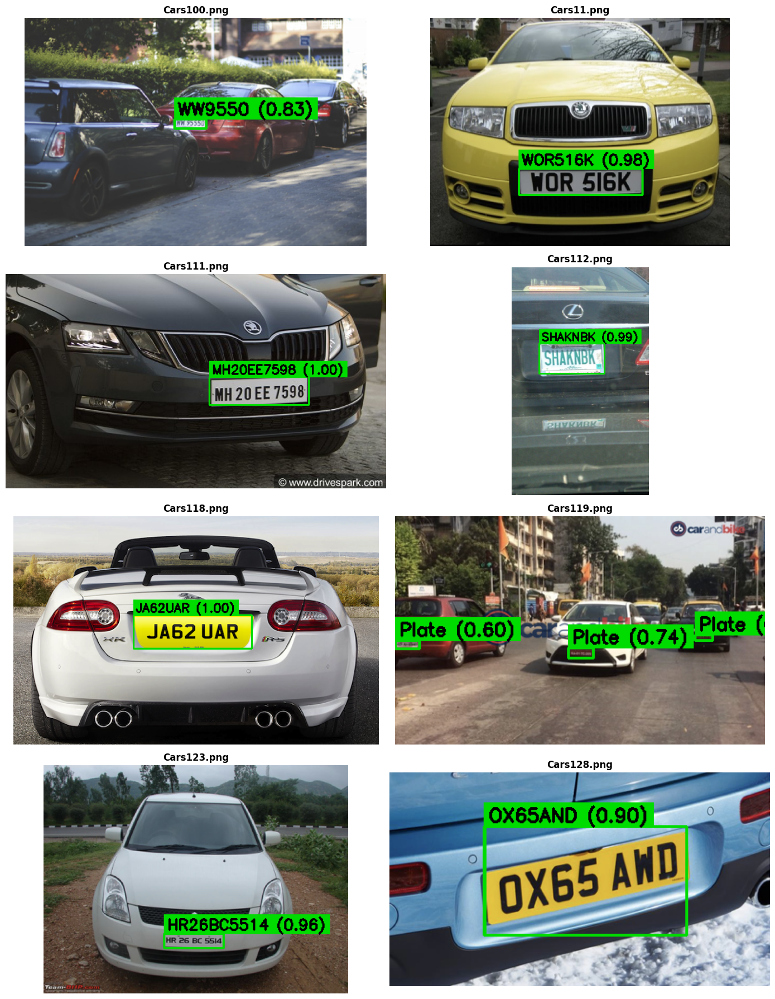

In [37]:
import csv, glob, os
import cv2, matplotlib.pyplot as plt

# 1. Print logged CSV results with safe column unpacking
with open("anpr_results.csv", "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)  # skip or print header
    print(f"{header[0]:<15} | {header[1]:<12} | {header[2]:<8} | {header[3]:<8} | {header[4]}")
    print("-" * 75)
    for row in reader:
        if len(row) >= 5:
            src, text, ocr_cf, det_cf, bbox = row
            print(f"{src:<15} | {text:<12} | OCR: {ocr_cf:<5} | Det: {det_cf:<5} | {bbox}")

# 2. Display annotated images inline
out_imgs = sorted(glob.glob("anpr_outputs/*"))[:8]
cols = 2
rows = (len(out_imgs) + 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4.5))
for ax, p in zip(axes.flat, out_imgs):
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(p), fontweight="bold")
    ax.axis("off")
for ax in axes.flat[len(out_imgs):]:
    ax.axis("off")
plt.tight_layout()
plt.show()